# Overview of Visualization

## Prerequisites

In [1]:
# HIDE/SHOW
# ! pip install -U numpy
# ! pip install -U matplotlib

## Visualization in Python

The folder of this notebook holds a small module, `simscene`, with the scenes of this course, two renderers and the charts. It needs NumPy and matplotlib only: every picture on this page is drawn by the notebook, not by Isaac Sim. Labels are set in Computer Modern through matplotlib's mathtext, so no TeX installation is needed.

In [2]:
# HIDE/SHOW
import warnings
warnings.filterwarnings('ignore')

from simscene import show, LabScene
from simscene import Terrain, ColourMaps, DepthCubes, Contours, Throw, InertiaBox, BallAndRing, Glyphs, RayFans
from simscene import DatasetDiagram, PipelineDiagram, ColliderDiagram
from simscene import BrightnessChart, DepthImages, ContourChart, IntegrationChart, TimestepChart, FieldChart, ProbeChart, ReductionChart

import scenes                      # labs/scenes.py: what each lab shows (simscene puts labs/ on the path)

## Utilizations

The module is built from a few small class families. Each has one method that its subclasses override, so one call, `show(...)`, does the right thing for every member.

| | Base class | Subclasses | Overridden |
|---|---|---|---|
| **Picture** | `Picture` | `Scene`, `Chart` | `bundle()`: what the cell displays |
| **Scene** | `LabScene` | `Terrain`, `ColourMaps`, `DepthCubes`, `Contours`, `Throw`, `InertiaBox`, `BallAndRing`, `Glyphs`, `RayFans` | `build()`: the shapes and the camera of one lab |
| **Renderer** | `Renderer` | `Still`, `Canvas`, `Stage` | `draw(scene)`: a still picture, a canvas for the page, or prims on a USD stage |
| **Chart** | `Chart` | `BrightnessChart`, `DepthImages`, `ContourChart`, `IntegrationChart`, `TimestepChart`, `FieldChart`, `ProbeChart`, `ReductionChart` | `plot(fig)`: the drawing on a matplotlib figure |
| **Diagram** | `Diagram` | `DatasetDiagram`, `PipelineDiagram`, `ColliderDiagram` | `plot(fig)`: boxes, arrows and text on one sheet |

Every scene comes from one function of `labs/scenes.py`, the file that the lab scripts read on the DGX Spark, so this page and the simulator are given the same scene. A new scene is a subclass of `LabScene` with its own `build`; its first docstring line is its caption.

A 3D picture on this page can be turned. Drag it to turn the scene, Shift-drag to move it, click and then scroll to zoom, double-click to go back to the scene's own camera. Where the page cannot run scripts, the same scene appears as a still picture.

## What is Visualization?

- Visualization turns data into pictures that people can read.
- A visualization algorithm is a transformation: data goes in, different data comes out, and at the end something can be drawn.
- On this page each algorithm is a lab that you run inside Isaac Sim.

This page is adapted from Chapter 1, "Overview of Visualization" (W. J. Schroeder and K. M. Martin), in Hansen and Johnson (eds.), *The Visualization Handbook*, Elsevier, 2005. It keeps the handbook's order. The ideas are the handbook's; the wording, code and figures are new, and every example is a robot-simulation one.

## Types of Algorithms

The handbook sorts the classic algorithms into four families, by the kind of data they work on.

| | Data | Labs |
|---|---|---|
| **Scalar** | one number per sample: a height, a depth | 2, 3, 4 |
| **Vector** | a direction and a size per sample: a velocity | 5, 6 |
| **Tensor** | a $3 \times 3$ matrix per sample: an inertia | 7 |
| **Modeling** | algorithms that build, sample or reduce geometry | 8, 9, 10, 11 |

Lab 1 comes before the four families: it shows what a dataset is.

## The Labs at a Glance

You need the `isaac` environment from the page Isaac Sim on a DGX Spark. Nothing else is installed.

| | Handbook section | You run | Starts the simulator |
|---|---|---|---|
| **Lab 1** | 1.1 Datasets and transformations | `lab01_dataset.py` | yes |
| **Lab 2** | 1.1.2 Filters, 1.2.1 Colour mapping | `lab02_colormap.py` | yes |
| **Lab 3** | 1.2.1 Colour mapping of sensor data | `lab03_depth.py` | yes |
| **Lab 4** | 1.2.2 Contouring | `lab04_contour.py` | yes |
| **Lab 5** | 1.3.1 Hedgehogs, 1.3.5 Streamlines | `lab05_vectors.py` | yes |
| **Lab 6** | 1.3.4 Time integration | `lab06a_integration.py`, `lab06b_timestep.py` | part B |
| **Lab 7** | 1.4 Tensor ellipsoids | `lab07_inertia.py` | yes |
| **Lab 8** | 1.5.2 Implicit functions, 1.5.3 Implicit modeling | `lab08a_sdf.py`, `lab08b_colliders.py` | part B |
| **Lab 9** | 1.5.4 Glyphs | `lab09_glyphs.py` | yes |
| **Lab 10** | 1.5.6 Probing | `lab10_probe.py` | yes |
| **Lab 11** | 1.5.7 Data reduction | `lab11_reduction.py`, `lab01_dataset.py` | step 2 |

**What is folded.** Commands to type are always visible. Longer listings and expected outputs are folded: click a line with a triangle to open it. The code that draws the pictures of this page is folded in the same way.

<aside>

**What was tested, and where the pictures come from.** No Isaac Sim was available while writing this course. The scripts were checked against the Isaac Sim 6.2.0.0 Python source and run against real OpenUSD with a stand-in for the simulator. That exercises the script logic and everything written to the stage, but not the physics engine, the renderer, the sensors or the stream. Three kinds of output follow from that:

- Outputs of the NumPy-only scripts (`vizcore.py`, `lab06a`, `lab08a`, `lab11`) are quoted and real.
- Outputs that depend only on NumPy and on what is written to the stage (Labs 1, 2, 4 and 9) are quoted as the stand-in run printed them.
- Outputs that depend on physics, a sensor or a ray cast (Labs 3, 5, 6 B, 7, 8 B and 10) are described, not quoted. Your run supplies the numbers.

The 3D pictures on this page are *previews*, not Isaac Sim screenshots: each one is the scene a lab saves, drawn by the notebook from `labs/scenes.py`. Three scenes need numbers from the simulator and use stand-ins: Lab 5 (a recording made by a simple integrator), Lab 7 (the tensor from the formula) and Lab 10 (distances from the reference ray caster). The four depth pictures in Lab 3 are made from a depth image computed by a ray caster, `scenes.lab03_depth()`, for the same camera. The charts are computed by `labs/vizcore.py`, in plain NumPy.

</aside>

## Setup

### Get into the Lab Folder

```bash
# Spark
cd ~/ivcl/courses/sim
conda activate isaac
```

All commands below are run from this folder. Scripts write into `out/` next to `labs/`.

### Run the Self-Test

```bash
# Spark (isaac)
python labs/vizcore.py
```

<details>
<summary>Expected output</summary>

```text
terrain      1089 points, 1024 quads, height 0..0.53 m
lut viridis  brightness always increasing: True
lut rainbow  brightness always increasing: False
colour       sRGB (0.463, 0.725, 0) = linear [0.181 0.484 0.   ]
contour      164 segments, circle length 6.2822 (2*pi = 6.2832), ambiguous 0
integrate    euler radius after one turn: 1.3681 (exact 1.0)
integrate    rk2   radius after one turn: 1.0008 (exact 1.0)
inertia      principal moments [0.0483 0.0667 0.1017]
ring mesh    volume 0.05874 m^3 (exact 0.05890)
glyphs       1089 quaternions rotate +Z onto normals
physics      drop lands at t = 0.617 s; a throw at 3 m/s rises to 0.75 m
probe        centre ray hits the box at 2.5 m
all vizcore self-tests passed
```

</details>

`vizcore.py` is plain NumPy and does not start the simulator. Each line is one algorithm of this page checking itself against a known answer. Keep the file open in an editor; the labs point into it.

### Know the Four Files Every Lab Uses

| | What is in it |
|---|---|
| `labs/vizcore.py` | The algorithms: lookup tables, marching squares, integrators, distance fields, a reference ray caster. Plain NumPy. |
| `labs/scenes.py` | What each lab shows: `lab02()`, `lab04()` and so on, each returning a list of meshes and a camera. |
| `labs/look.py` | How a scene is put on the stage: `usd_scene()` writes the meshes, a matte material, the camera and the light. |
| `labs/simlab.py` | The Isaac Sim boilerplate: `start()`, `new_stage()`, `show()`, `collide()`, `save()`, `finish()`. |

Every lab has the same skeleton. Read it once here. `start()` must run before anything else from `isaacsim` or `pxr` is imported. If you change what a lab shows, change it in `scenes.py`.

<details>
<summary>Listing: labs/lab02_colormap.py, the skeleton of every lab</summary>

```python
from simlab import finish, new_stage, parse_args, save, show, start

args = parse_args(n=65)
app = start(args.stream)
```

```python
stage = new_stage()

# SOURCE and FILTER live in scenes.lab02(): a terrain, and its
# height pushed through two lookup tables.
prims, view = scenes.lab02(args.n)

# SINK: the coloured meshes go on the stage; the renderer draws.
show(stage, prims, view)
```

</details>

### Decide How You Will Look at Results

**Live, in the stream.** Add `--stream` to any lab that starts the simulator. The script builds its scene, then keeps running and streams it through the scene's camera. Connect the Isaac Sim WebRTC Streaming Client on the Mac to the Spark's address, as in Step 4 of the page Isaac Sim on a DGX Spark. Press Ctrl-C in the terminal when you have seen enough. Only one stream can run at a time.

**As a file.** Every lab saves its scene as `out/labNN.usda`. The capture script of that Step 4 turns any of them into a picture of 1280 by 720 pixels:

```bash
# Spark (isaac)
python labs/s4_shot.py out/lab02.usda out/lab02.png
```

```bash
# Mac
scp spark:ivcl/courses/sim/out/lab02.png . && open lab02.png
```

**One theme.** Every lab takes `--theme light` (the default) or `--theme dark`. Use one theme for the whole session.

## Lab 1: What a Dataset Is

Handbook 1.1.

**The idea.** Any dataset has three parts. *Topology* says which samples are connected. *Geometry* says where they are. *Attributes* are the data they carry. Algorithms are classified by which parts they change: geometric, topological, attribute, or combined. A USD mesh stores the three parts as separate attributes, so you can watch each one change.

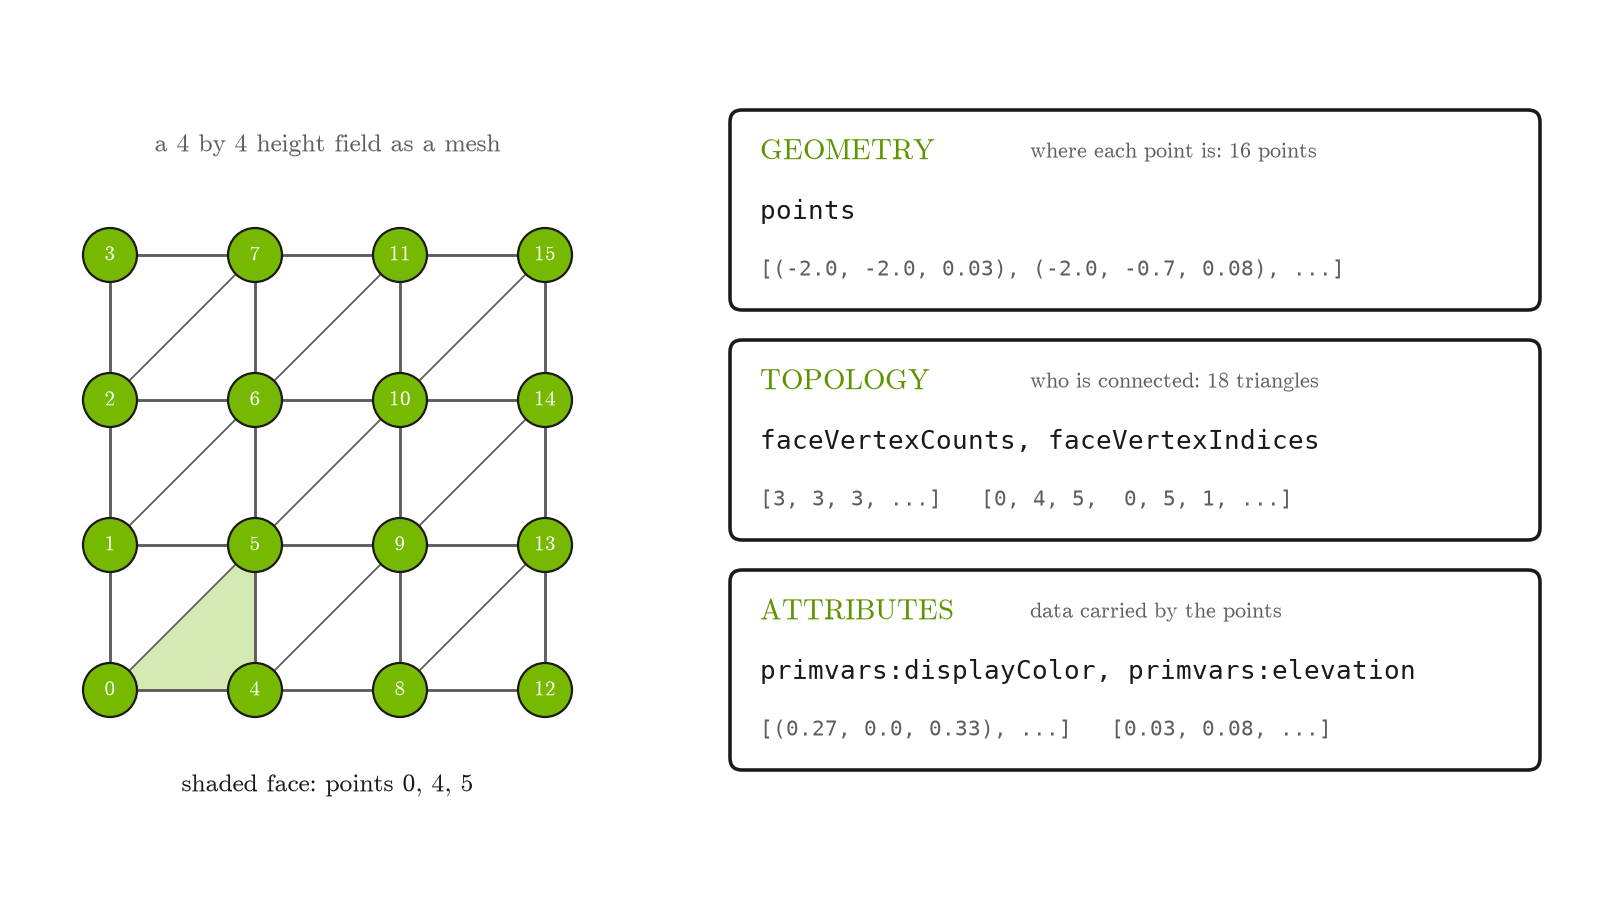

In [3]:
# HIDE/SHOW
show(DatasetDiagram())

| | What it says | In a USD mesh |
|---|---|---|
| **Geometry** | where each point is | `points` |
| **Topology** | which points form a face | `faceVertexCounts`, `faceVertexIndices` |
| **Attributes** | the data carried by the points | `primvars:displayColor`, `primvars:elevation` |

**In symbols.** The source of this page's terrain is a height field, two bumps and a ripple, sampled on a grid of $n \times n$ points and shifted so that its lowest point is at height 0:

$$
\begin{aligned}
z(x, y) = {} & 0.45\,\exp\!\left(-\frac{(x - 0.6)^2 + (y - 0.5)^2}{0.5}\right)
             + 0.30\,\exp\!\left(-\frac{(x + 0.9)^2 + (y + 0.7)^2}{0.3}\right) \\
             & + 0.05\,\sin(2.5\,x)\cos(2\,y)
\end{aligned}
$$

With $n = 65$ that is $65^2 = 4225$ points and $2 \times 64^2 = 8192$ triangles.

**Steps.**

1. Build a terrain mesh on the stage and apply two transformations to it. The last two lines of output give the saved file, `out/lab01.usda`, and its size.

    ```bash
    # Spark (isaac)
    python labs/lab01_dataset.py
    ```

    <details>
    <summary>Expected output</summary>

    ```text
    --- the dataset ---
    geometry : points              (4225, 3)
    topology : faceVertexCounts    (8192,)  (all 3-sided)
    topology : faceVertexIndices   (24576,)
    first face uses points [ 0 65 66]
    attribute: primvars:displayColor  (one colour per point)
    --- after a geometric transformation (z * 2) ---
    max height   : 0.528 -> 1.056
    topology same: True
    --- after an attribute transformation (elevation) ---
    new attribute: primvars:elevation (4225 values, one per point)
    geometry same: True  topology same: True
    ```

    </details>

2. Find the three parts in the saved file. Each `grep` should print at least one line.

    ```bash
    # Spark
    grep -n "point3f\[\] points" out/lab01.usda | cut -c1-80
    grep -n "faceVertexIndices" out/lab01.usda | cut -c1-80
    grep -n "primvars:elevation" out/lab01.usda | cut -c1-80
    ```

3. Open `labs/lab01_dataset.py` and find the three comments `SOURCE`, `GEOMETRIC transformation` and `ATTRIBUTE transformation`. The geometric one is two lines.

    <details>
    <summary>Listing: labs/lab01_dataset.py, the geometric transformation</summary>

    ```python
    # GEOMETRIC transformation: double every height.
    taller, _ = scenes.lab01(args.n, args.stride, taller=True)
    mesh.GetPointsAttr().Set(taller[0]["points"].tolist())
    ```

    </details>

4. Run it again keeping only every fourth sample in each direction. The points shrink from 4225 to 289.

    ```bash
    # Spark (isaac)
    python labs/lab01_dataset.py --stride 4
    ```

5. Look at it: run step 1 again with `--stream` and connect the client.

**What it looks like.** The scene the lab saves, `out/lab01.usda`:

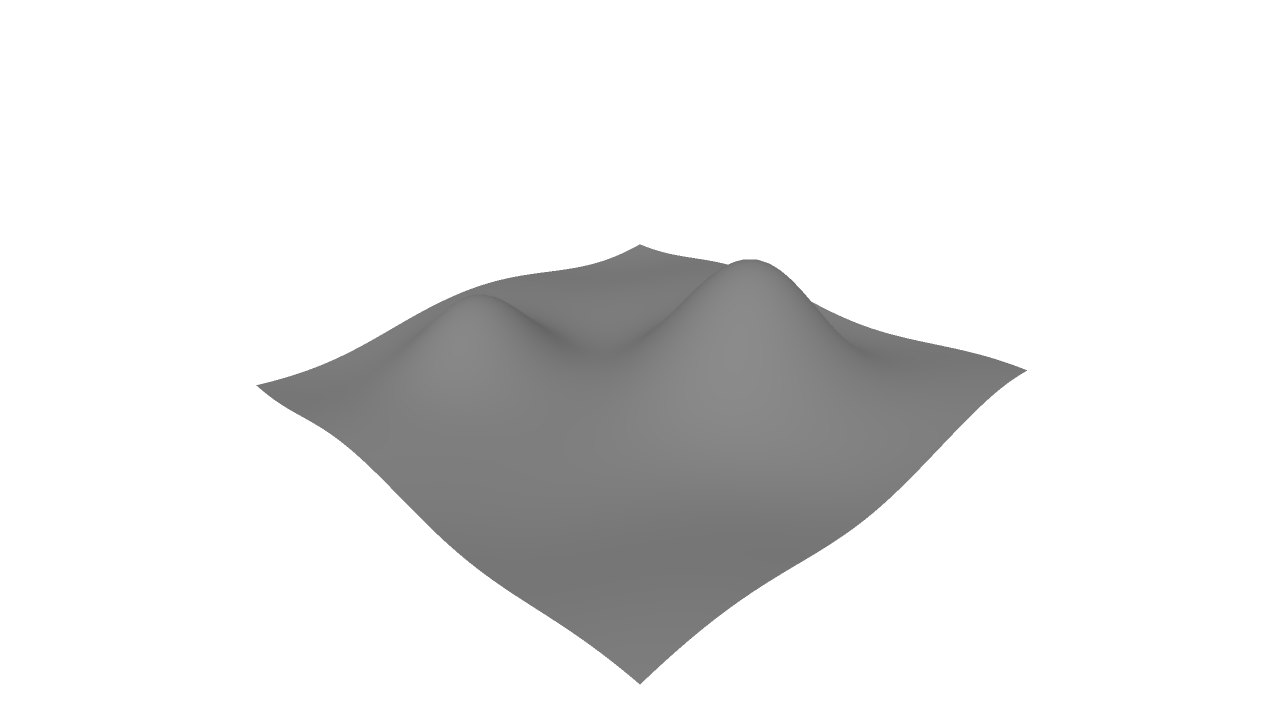

In [4]:
# HIDE/SHOW
show(Terrain())

| | Before | After the geometric transformation |
|---|---|---|
| **Points** | $65^2 = 4225$ | 4225, every height doubled |
| **Triangles** | $2 \times 64^2 = 8192$ | unchanged |
| **Largest height** | 0.528 m | 1.056 m |

**Check yourself.**

- Doubling the heights changed the points and left both topology arrays identical. Which of the four kinds of transformation is that?
- `--stride 4` changed all three arrays. Which kind is that?
- A lidar point cloud has geometry and attributes. What is its topology?

## Lab 2: A Pipeline, and Colour Mapping

Handbook 1.1.2 and 1.2.1.

**The idea.** Visualization systems are pipelines. A *source* creates data, *filters* turn data into other data, and a *sink* hands the result to the renderer. Colour mapping is the simplest filter: clamp a scalar to a range, normalise it, and look the result up in a table of colours. The choice of table changes what people see.

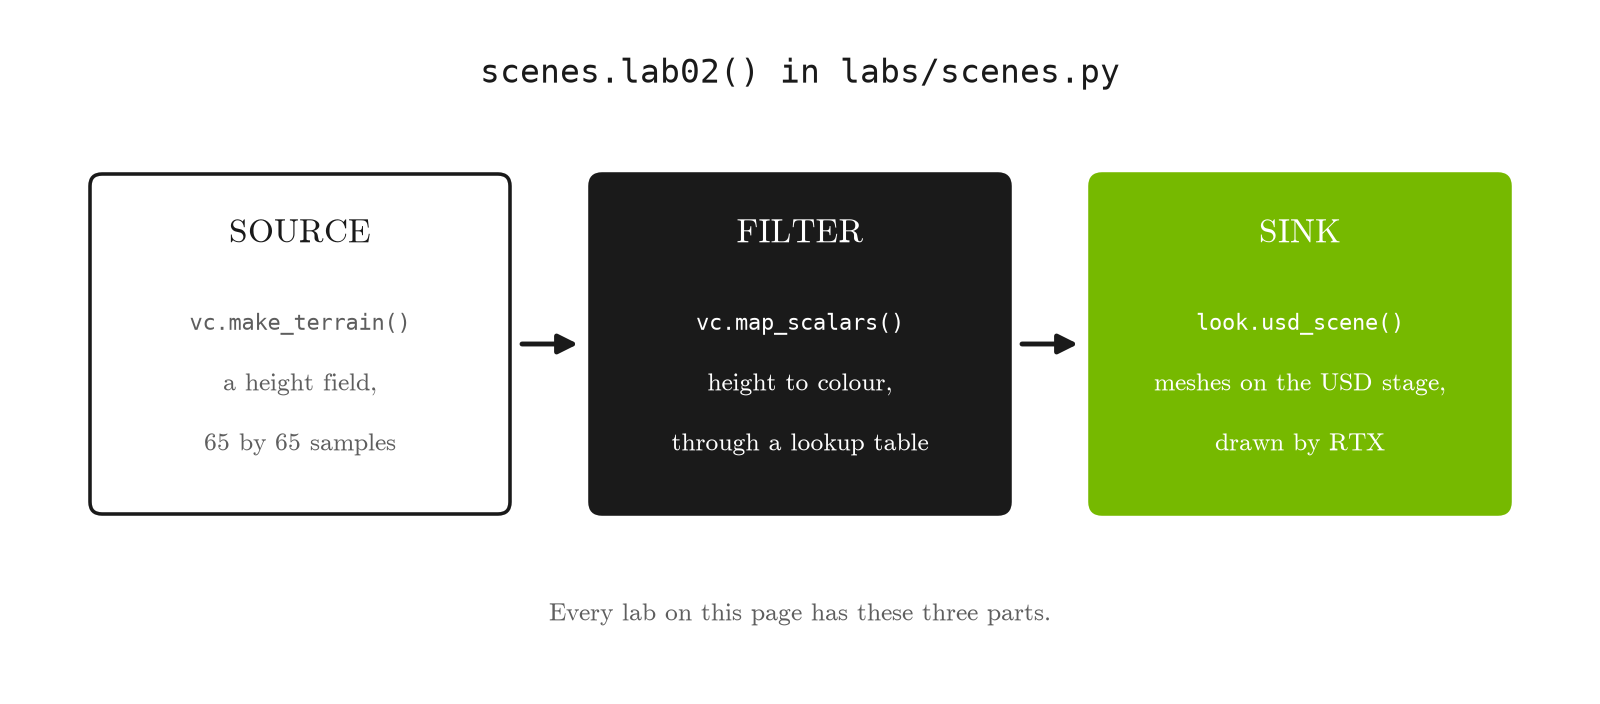

In [5]:
# HIDE/SHOW
show(PipelineDiagram())

| | In the handbook | In this lab |
|---|---|---|
| **Source** | creates data | `vc.make_terrain()`: a height field of 65 by 65 samples |
| **Filter** | turns data into other data | `vc.map_scalars()`: a height becomes a colour |
| **Sink** | hands the result to the renderer | `look.usd_scene()`: meshes on the USD stage |

**In symbols.** A value $v$ in the range from $v_{\min}$ to $v_{\max}$ becomes a number $s$ between 0 and 1 and then a colour:

$$
s = \operatorname{clamp}\!\left(\frac{v - v_{\min}}{v_{\max} - v_{\min}},\ 0,\ 1\right),
\qquad
\text{colour} = \operatorname{LUT}(s)
$$

The brightness of a colour is its luminance, and in a good table it rises steadily from one end to the other:

$$
Y = 0.2126\,R + 0.7152\,G + 0.0722\,B
$$

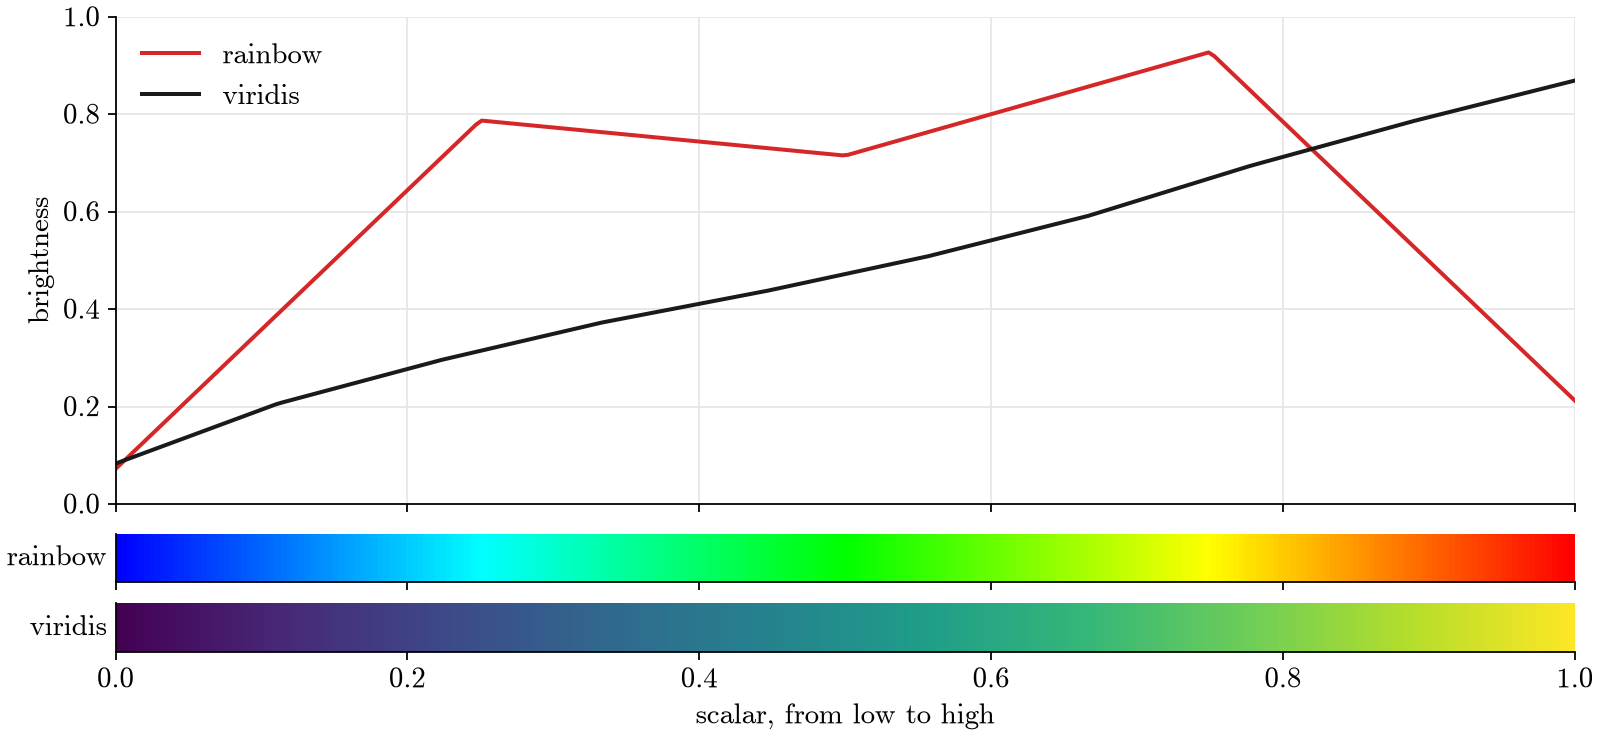

In [6]:
# HIDE/SHOW
show(BrightnessChart())

| | Brightness $Y$ from the low end to the high end | In a grey printout |
|---|---|---|
| **Rainbow** | rises and falls: it changes direction 3 times | two different heights can print as the same grey |
| **Viridis** | rises all the way | the order of the heights survives |

**Steps.**

1. Read the source and the filter. The scene is in `labs/scenes.py`, the filter is `map_scalars` in `labs/vizcore.py`.

    <details>
    <summary>Listing: lab02() in labs/scenes.py, and map_scalars() in labs/vizcore.py</summary>

    ```python
    def lab02(n=65):
        X, Y, Z = vc.make_terrain(n)
        scalar = Z                                   # colour by height
        lo, hi = float(scalar.min()), float(scalar.max())
        prims = []
        for name, lut, y in (("rainbow", vc.lut_rainbow, -2.2),
                             ("viridis", vc.lut_viridis, 2.2)):
            rgb = vc.map_scalars(scalar, lo, hi, lut)
            prims.append(look.height_field(name, X, Y, Z, rgb,
                                           origin=(0.0, y, 0.0)))
    ```

    ```python
    def map_scalars(values, vmin, vmax, lut=lut_viridis):
        """Clamp to [vmin, vmax], normalise, look up. Returns RGB."""
        s = (np.asarray(values, dtype=float) - vmin) / (vmax - vmin)
        return lut(s)
    ```

    </details>

2. Put the scene on the stage. The sink is one call, `show(stage, prims, view)`. Then connect the client: the terrain appears twice, rainbow on the left and viridis on the right.

    ```bash
    # Spark (isaac)
    python labs/lab02_colormap.py --stream
    ```

    <details>
    <summary>Expected output</summary>

    ```text
    rainbow  colour at the lowest point [0.   0.   0.87], at the highest [0.89 0.   0.  ]
    viridis  colour at the lowest point [0.23 0.   0.29], at the highest [0.88 0.8  0.13]
    rainbow  brightness changes direction 3 times
    viridis  brightness changes direction 0 times
    ```

    </details>

3. Change the filter. In `scenes.lab02()` replace `scalar = Z` with the line below and run step 2 again. The terrain is now coloured by slope. The handbook calls this *scalar generation* (1.2.3): when the data has no scalar worth mapping, compute one. Put the line back afterwards.

    ```python
    scalar = 1.0 - vc.grid_normals(X, Y, Z)[..., 2]
    ```

**What it looks like.** The scene the lab saves, `out/lab02.usda`:

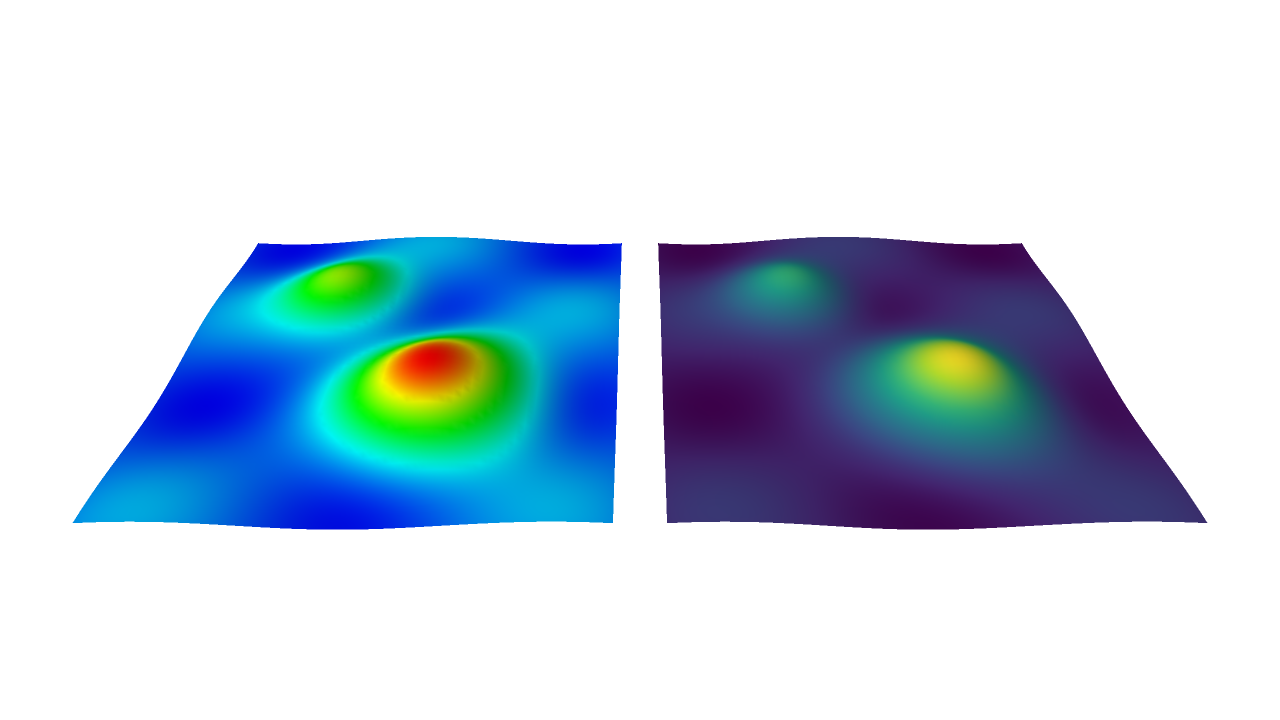

In [7]:
# HIDE/SHOW
show(ColourMaps())

| | Left | Right |
|---|---|---|
| **Table** | rainbow | viridis |
| **Lowest point** | blue | dark purple |
| **Highest point** | red | yellow |
| **Scalar** | the height $z$ | the same height $z$ |

**Check yourself.**

- In the rainbow version, find a sharp boundary between two colours. Is there an edge in the terrain at that place?
- From each half alone, which of the two hills is higher? Which table made that easier?
- The script says the rainbow's brightness changes direction three times. What does that do to a grey printout?
- In `look.usd_mesh()`, the colours pass through `linear()` before they are stored. Remove that call, run step 2 again and compare with the preview. What happened, and why? Put it back.

## Lab 3: Colour-Map a Depth Camera

Handbook 1.2.1.

**The idea.** A simulated depth camera returns one scalar per pixel: metres from the image plane. It is not a picture until you choose a range and a table. The range matters as much as the table.

**In symbols.** A depth $d$ is mapped like any other scalar, with a near and a far limit as the range:

$$
s = \operatorname{clamp}\!\left(\frac{d - d_{\text{near}}}{d_{\text{far}} - d_{\text{near}}},\ 0,\ 1\right)
$$

A fixed range uses the same limits for every frame, here 0 m and 8 m. An automatic range takes the smallest and the largest depth of the current frame.

What the depth camera looks at, the scene the lab saves as `out/lab03.usda`:

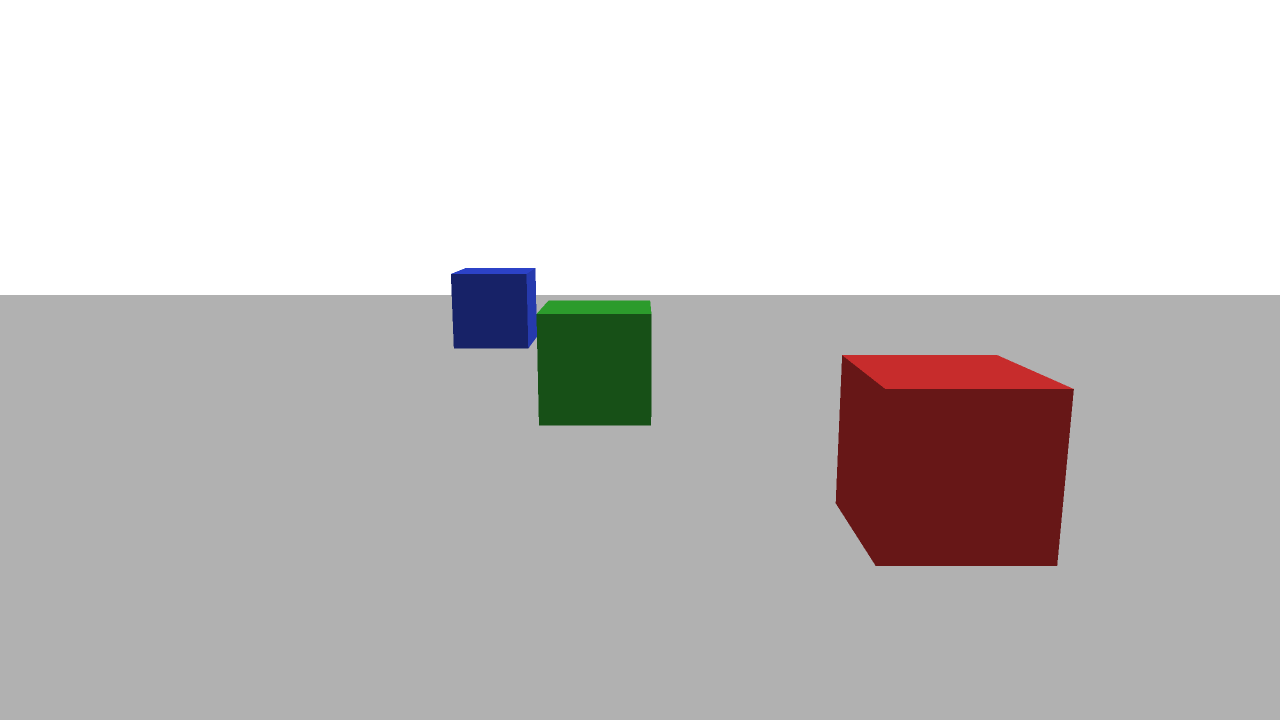

In [8]:
# HIDE/SHOW
show(DepthCubes())

| | Colour in the scene | Centre along the x axis |
|---|---|---|
| **Near cube** | red | 1.5 m |
| **Middle cube** | green | 3 m |
| **Far cube** | blue | 5 m |
| **Camera** | the view of this picture | at $x = -1$ m, 1 m above the ground |

**Steps.**

1. Read how the sensor is attached. It looks through the scene's own camera.

    <details>
    <summary>Listing: labs/lab03_depth.py, the depth sensor</summary>

    ```python
    # The depth sensor looks through the same camera as the pictures.
    H, W = look.HEIGHT // 2, look.WIDTH // 2      # (height, width)
    sensor = CameraSensor("/World/Camera", resolution=(H, W),
                          annotators=["distance_to_image_plane"])
    ```

    </details>

2. Capture one depth image of the three cubes.

    ```bash
    # Spark (isaac)
    python labs/lab03_depth.py
    ```

    The script prints the image shape, `(360, 640)`, the nearest and farthest depth, and how many pixels hit nothing (they come back as infinity). It writes `out/depth.npy`, `out/lab03.usda` and four pictures, two lookup tables times two ranges. If it says Pillow is not installed, run `pip install pillow` and repeat.

3. Look at the four pictures on the Mac.

    ```bash
    # Mac
    scp "spark:ivcl/courses/sim/out/depth_*.png" . && open depth_*.png
    ```

4. Move the far cube. In `scenes.py` change the last entry of `LAB03_CUBES` from `(5.0, 1.0, 0.25)` to `(7.0, 1.0, 0.25)`. Move the four pictures you have into a folder `before/`, then repeat steps 2 and 3 and compare old with new.

**What it looks like.** The four pictures the lab writes. They are made here from a depth image computed by a ray caster for the same camera and the same cubes, not captured in Isaac Sim. Pixels with no hit are white.

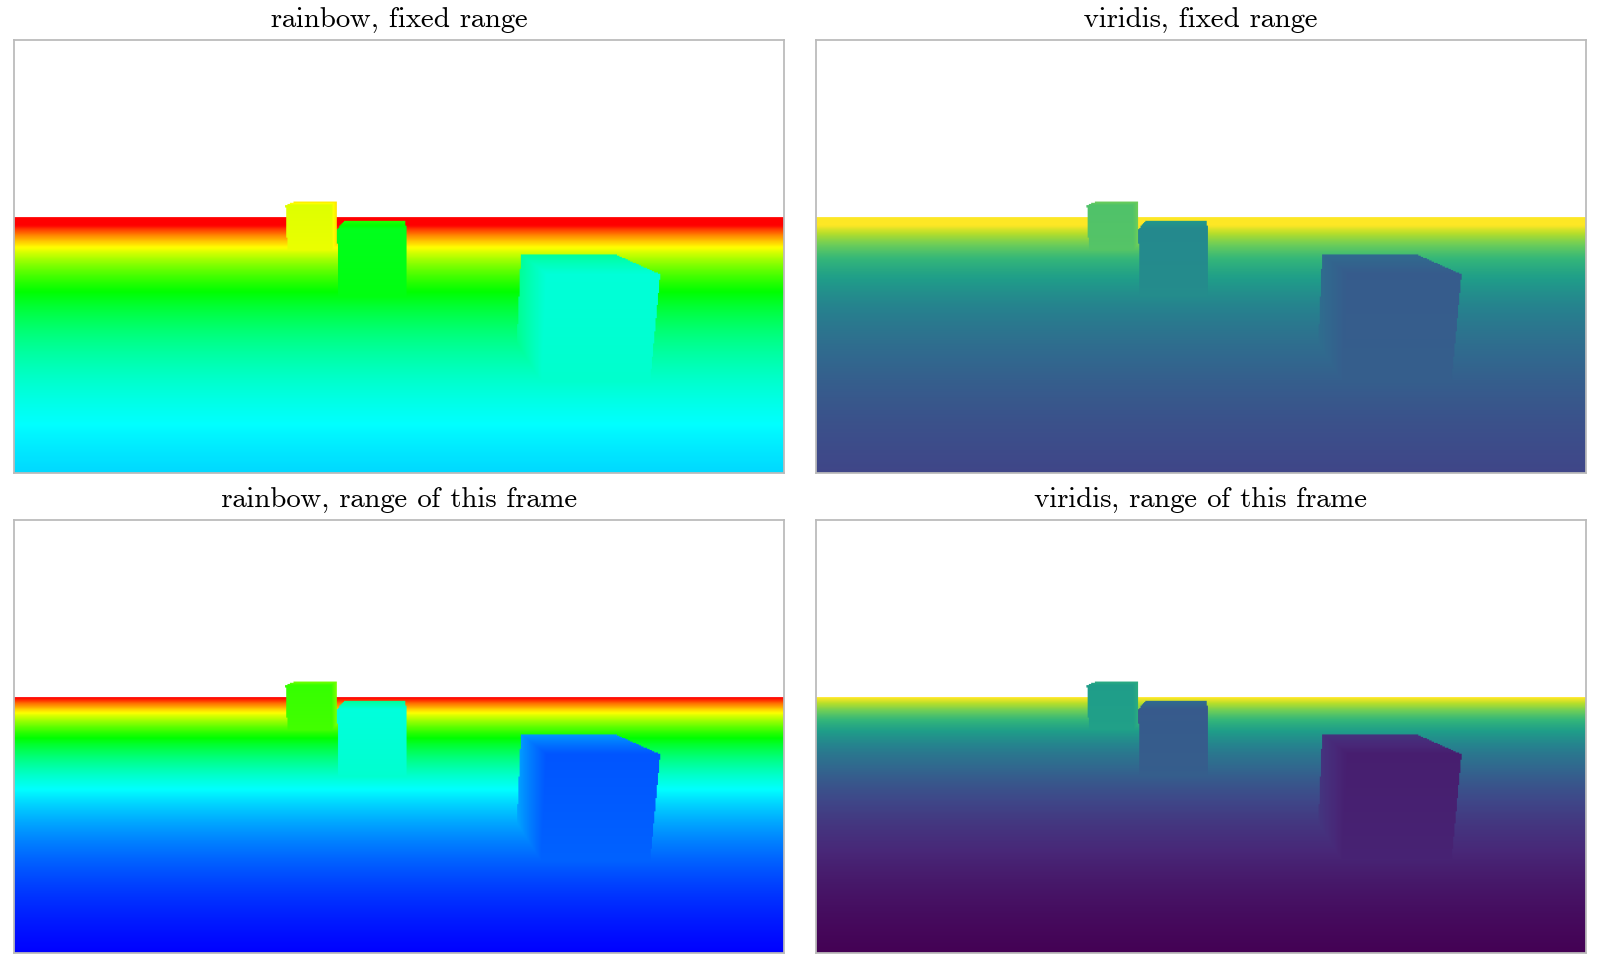

In [9]:
# HIDE/SHOW
show(DepthImages())

| | Fixed range | Range of this frame |
|---|---|---|
| **Limits** | $d_{\text{near}} = 0$ m and $d_{\text{far}} = 8$ m | the smallest and the largest depth of the image |
| **Rainbow** | `depth_rainbow.png` | `depth_rainbow_auto.png` |
| **Viridis** | `depth_viridis.png` | `depth_viridis_auto.png` |

**Check yourself.**

- In the two `_auto` pictures, did the two near cubes change colour when only the far cube moved? Did they in the two fixed-range pictures?
- A robot's depth display flickers from frame to frame. Which range setting causes that, and why?
- What should the picture show for pixels with no hit? What does `vc.depth_to_rgb` do with them?

## Lab 4: Contouring

Handbook 1.2.2.

**The idea.** A contour is where a scalar field equals a chosen value. Marching squares finds it one grid cell at a time: mark each corner as above or below the value, use the pattern of four marks to pick one of 16 cases, and place the line's crossing on each edge by linear interpolation. Two of the 16 cases are ambiguous. In 3D the same idea is marching cubes, and it is how a signed distance field becomes a collision surface.

**In symbols.** Four corners that are each above or below the level $c$ give $2^4 = 16$ cases. On an edge that the contour crosses, the crossing point is found by linear interpolation of the field values $F_p$ and $F_q$ at the two corners:

$$
w = \frac{c - F_p}{F_q - F_p},
\qquad
\mathbf{x} = \mathbf{x}_p + w\,(\mathbf{x}_q - \mathbf{x}_p)
$$

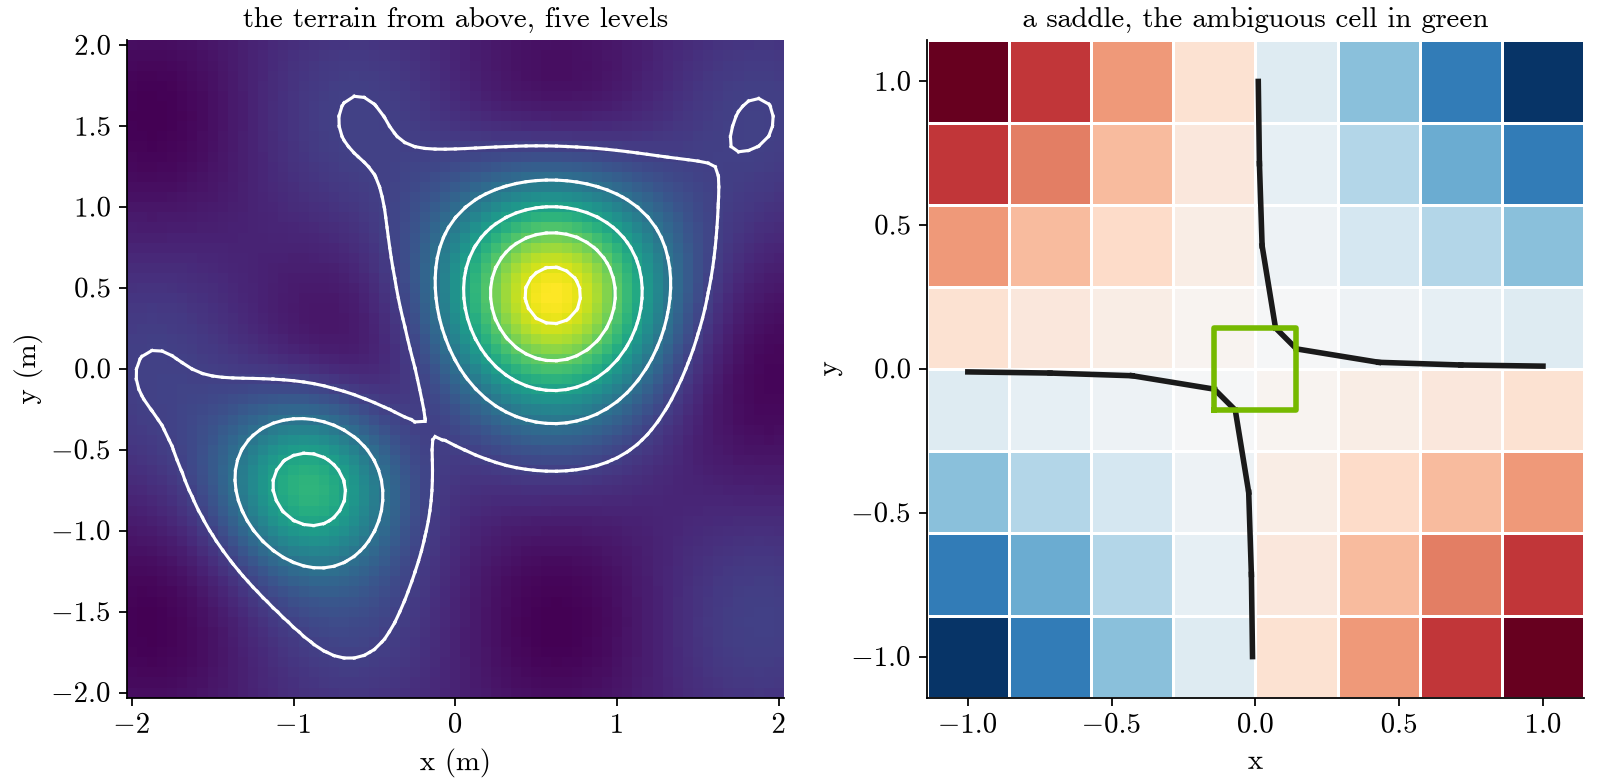

In [10]:
# HIDE/SHOW
show(ContourChart())

| | Left: the terrain from above | Right: a saddle |
|---|---|---|
| **Field** | the height $z(x, y)$ of Lab 1 | $F(x, y) = x\,y - 0.01$ on a grid of 8 by 8 samples |
| **Levels** | $c = 0.1,\ 0.2,\ 0.3,\ 0.4,\ 0.5$ m | $c = 0$ |
| **Ambiguous cells** | none | one, outlined in green |

**Steps.**

1. Read the algorithm: the case table in `labs/vizcore.py`, and the function under it.

    <details>
    <summary>Listing: labs/vizcore.py, the 16 cases of marching squares</summary>

    ```python
    _MS_CASES = {
        0: [], 15: [],
        1: [(3, 0)], 14: [(3, 0)],
        2: [(0, 1)], 13: [(0, 1)],
        4: [(1, 2)], 11: [(1, 2)],
        8: [(2, 3)], 7: [(2, 3)],
        3: [(3, 1)], 12: [(3, 1)],
        6: [(0, 2)], 9: [(0, 2)],
        5: None, 10: None,          # the two ambiguous cases
    }
    _MS_EDGES = [(0, 1), (1, 2), (2, 3), (3, 0)]
    ```

    </details>

2. Contour the terrain at five heights and lay the lines on it. Then connect the client: white contour lines lie on the coloured terrain. The lines are thin rods, so they are part of the scene and of `out/lab04.usda`.

    ```bash
    # Spark (isaac)
    python labs/lab04_contour.py --stream
    ```

    <details>
    <summary>Expected output</summary>

    ```text
    level 0.1 m:  286 segments, 0 ambiguous cells
    level 0.2 m:  152 segments, 0 ambiguous cells
    level 0.3 m:  104 segments, 0 ambiguous cells
    level 0.4 m:   50 segments, 0 ambiguous cells
    level 0.5 m:   24 segments, 0 ambiguous cells
    wrote out/contours.npz
    saddle: 1 ambiguous cell, resolved correctly: True
    ```

    </details>

3. Break it on purpose. In `marching_squares` in `labs/vizcore.py`, swap the two `pairs = ...` lines in the ambiguous branch and run step 2 again (without `--stream`). The terrain numbers are unchanged, because the terrain has no ambiguous cells, but the last line now reads `resolved correctly: False`. Undo the change.

**What it looks like.** The scene the lab saves, `out/lab04.usda`:

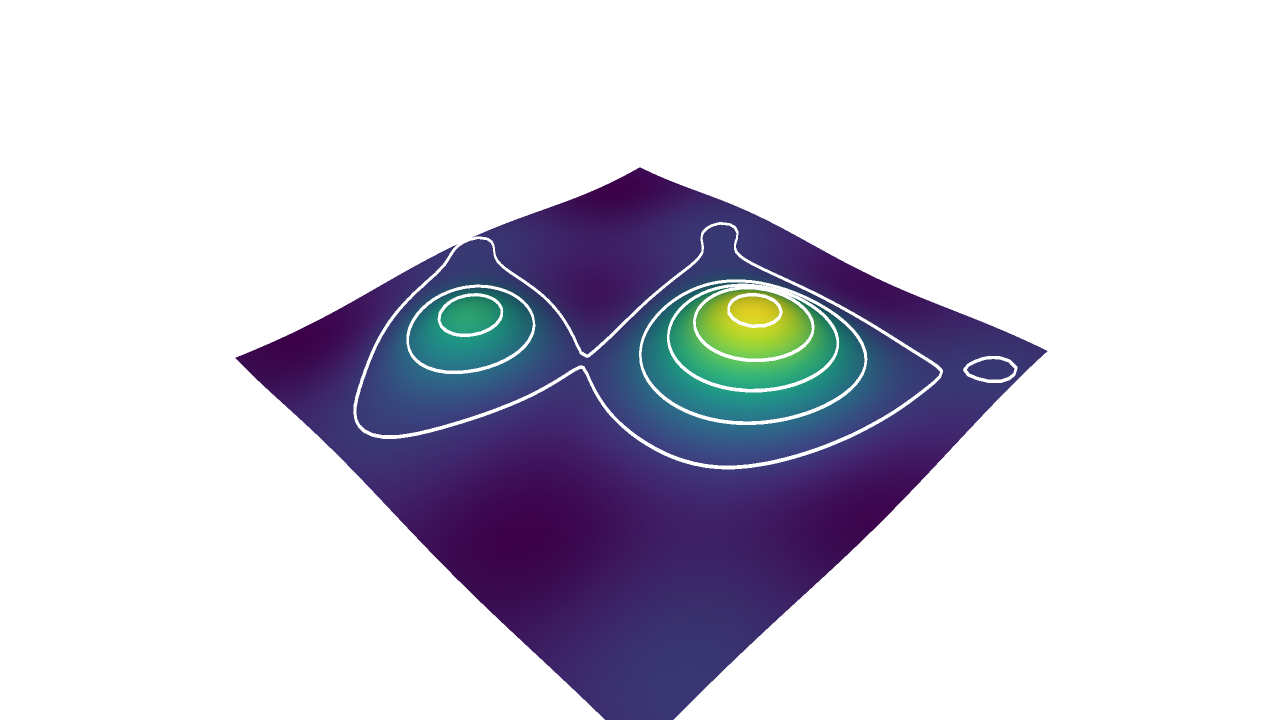

In [11]:
# HIDE/SHOW
show(Contours())

| | In the picture | In the file |
|---|---|---|
| **Terrain** | coloured by height with viridis | one mesh, one colour per point |
| **Contours** | white lines at five heights | thin rods: 616 segments in all |

**Check yourself.**

- Why do the two ambiguous cases need extra information, and what does the code use?
- The 0.1 m level has the most segments. Why?
- The terrain is 65 by 65 samples. Run the lab with `--n 9`. What happened to the 0.5 m contour?

## Lab 5: Vectors, Hedgehogs and Pathlines

Handbook 1.3.1 and 1.3.5.

**The idea.** A vector has a direction and a size. The most direct picture is a *hedgehog*: one line per sample, pointing along the vector. To see where things go over time you connect successive positions into a *pathline*. Colour can carry speed.

**In symbols.** Each cube starts with a velocity that swirls around the vertical axis and points upward:

$$
\mathbf{v}_0(x, y) = (-1.5\,y,\ \ 1.5\,x,\ \ 3)\ \text{m/s}
$$

A hedgehog line runs from a position $\mathbf{x}$ to $\mathbf{x} + k\,\mathbf{v}$ with the scale $k = 0.08$ s, and a pathline is coloured by the speed $\lVert \mathbf{v} \rVert$ along it.

**Steps.**

1. Read how the data is recorded: one position and one velocity per body, per physics step.

    <details>
    <summary>Listing: labs/lab05_vectors.py, the recording</summary>

    ```python
    t, pos, vel = [], [], []
    for _ in range(STEPS):
        SimulationManager.step()
        p, _quat = bodies.get_world_poses()
        v, _omega = bodies.get_velocities()
        t.append(SimulationManager.get_simulation_time())
        pos.append(to_np(p).copy())
        vel.append(to_np(v).copy())
    ```

    </details>

2. Throw 25 cubes in a swirl and record every step.

    ```bash
    # Spark (isaac)
    python labs/lab05_vectors.py --stream
    ```

    The script prints `recorded 120 steps x 25 bodies` and the range of speeds. After the run it adds two things to the scene as thin rods: one pathline per cube, coloured by speed, and a white hedgehog showing every cube's velocity at step 30. Connect the client to see them.

3. Make it unreadable. In `scenes.lab05_overlay()` change the defaults `every=4` to `every=1` and `scale=0.08` to `scale=0.5`, then run step 2 again. Put the values back afterwards.

**What it looks like.** The scene the lab saves, `out/lab05.usda`. The recording in this picture is a stand-in made by a simple integrator, `scenes.lab05_recording()`, not by Isaac Sim's physics; yours will differ in detail, most of all after the cubes land.

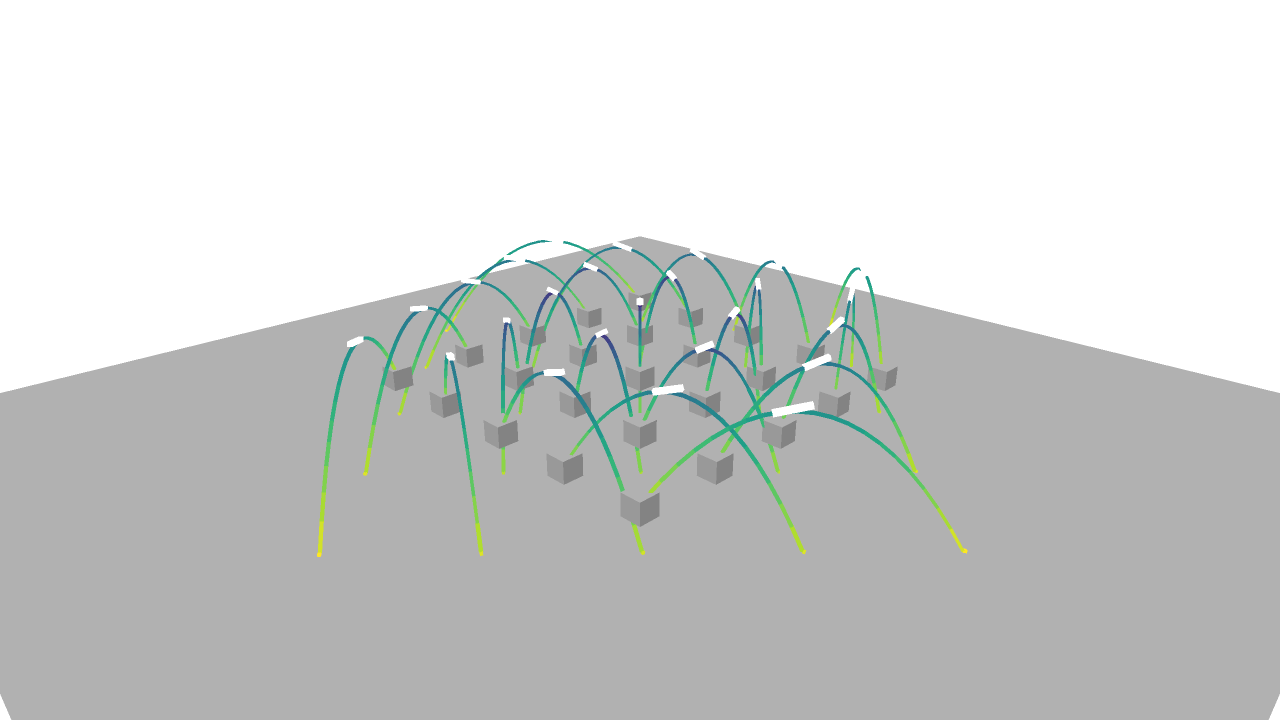

In [12]:
# HIDE/SHOW
show(Throw())

| | What is drawn | What it encodes |
|---|---|---|
| **Cubes** | 25 grey cubes on a grid of 5 by 5 | where each throw starts |
| **Pathlines** | one line per cube | where it went; the colour is the speed $\lVert \mathbf{v} \rVert$ |
| **Hedgehog** | white lines at step 30 | from $\mathbf{x}$ to $\mathbf{x} + k\,\mathbf{v}$ with $k = 0.08$ s |

**Check yourself.**

- Along a pathline, where is the colour brightest? What does that tell you?
- The hedgehog shows one instant. What does it hide that the pathlines show?
- After step 3, the same data is on screen. Why is it harder to read? The handbook's example is 167,000 vectors in an artery.

## Lab 6: Integration and the Time Step

Handbook 1.3.4.

**The idea.** To follow a particle through a velocity field you integrate. Euler's method steps along the current velocity; its error grows with the step. A second-order Runge-Kutta step averages the velocity at both ends and is far more accurate for the same step. A physics engine is an integrator too, and its time step plays the same role.

**In symbols.** For a particle at $\mathbf{x}_k$ in a velocity field $\mathbf{v}$ and a step $\Delta t$ the two methods are

$$
\begin{aligned}
\text{Euler:} \quad & \mathbf{x}_{k+1} = \mathbf{x}_k + \Delta t\,\mathbf{v}(\mathbf{x}_k) \\
\text{Runge-Kutta 2:} \quad & \mathbf{x}_{k+1} = \mathbf{x}_k + \frac{\Delta t}{2}\,\Bigl(\mathbf{v}(\mathbf{x}_k) + \mathbf{v}\bigl(\mathbf{x}_k + \Delta t\,\mathbf{v}(\mathbf{x}_k)\bigr)\Bigr)
\end{aligned}
$$

Part A uses the field $\mathbf{v}(x, y) = (-y,\ x)$ whose exact paths are circles.

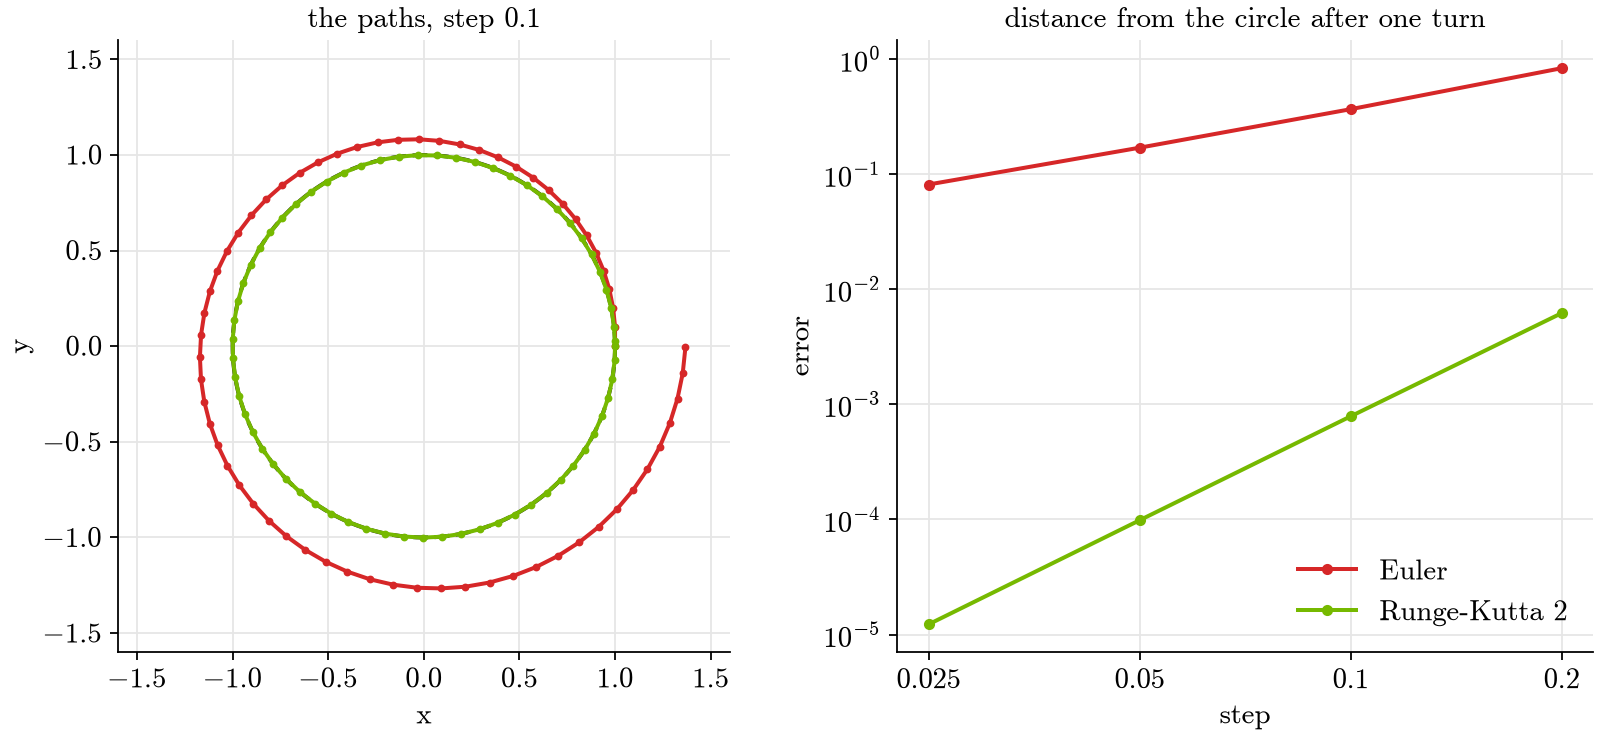

In [13]:
# HIDE/SHOW
show(IntegrationChart())

| | Radius after one turn, step 0.1 | Error at the steps 0.2, 0.1, 0.05 and 0.025 |
|---|---|---|
| **Exact** | 1 | none: the path is a circle |
| **Euler** | 1.3681 | the upper line of the right panel |
| **Runge-Kutta 2** | 1.0008 | the lower line of the right panel |

Part B drops a cube with edge $s = 0.3$ m from the height $z_0 = 2$ m, for which the exact height while falling and the impact time are

$$
z(t) = z_0 - \tfrac{1}{2}\,g\,t^2,
\qquad
t_{\text{impact}} = \sqrt{\frac{2\,(z_0 - s/2)}{g}} = 0.6141\ \text{s}
$$

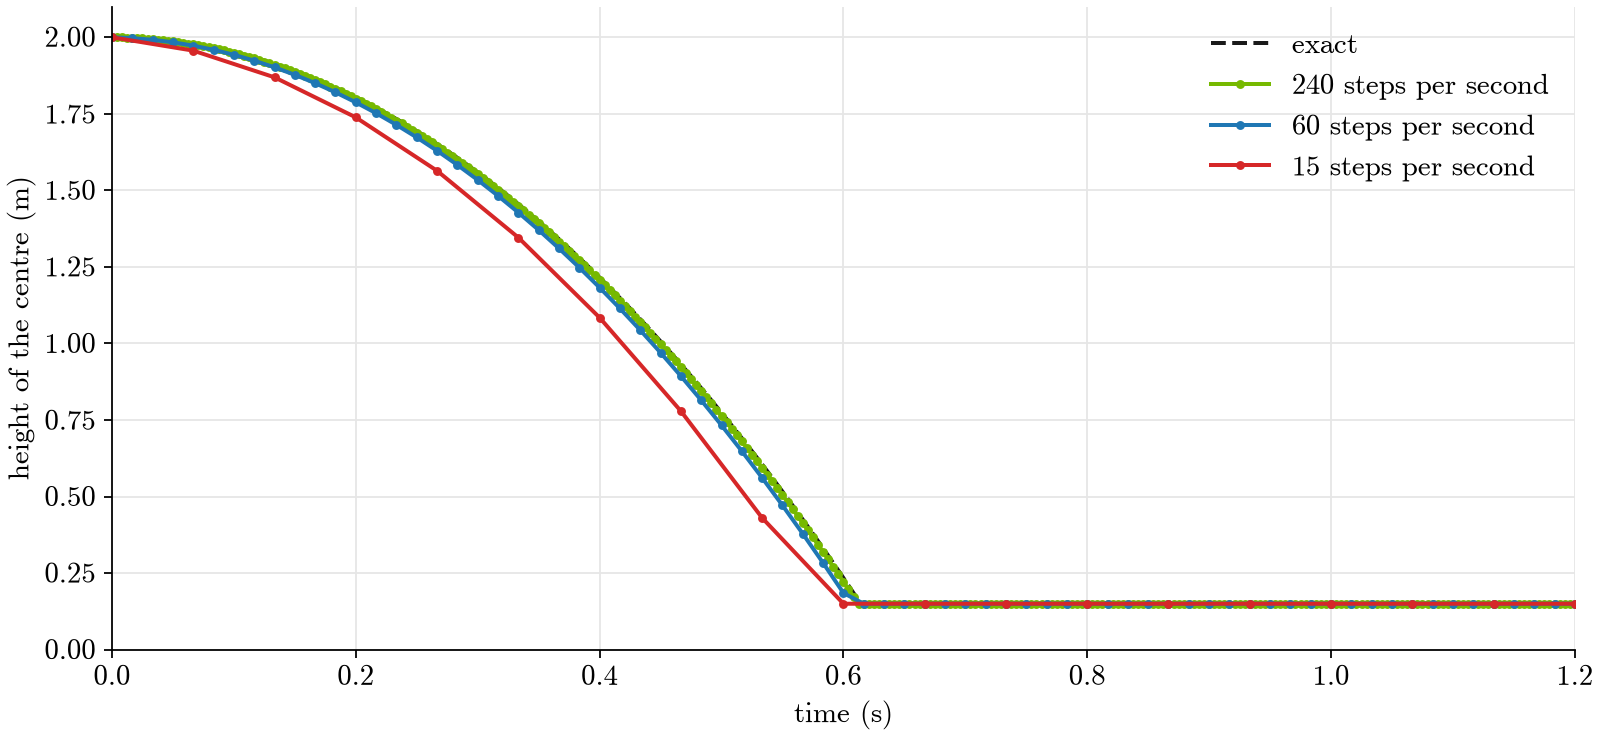

In [14]:
# HIDE/SHOW
show(TimestepChart())

| | Time step $\Delta t$ | Gap to the formula at $t = 0.4$ s |
|---|---|---|
| **240 steps per second** | 0.00417 s | 0.82 cm |
| **60 steps per second** | 0.01667 s | 3.27 cm |
| **15 steps per second** | 0.06667 s | 13.08 cm |

The three curves of this chart are a plain loop in NumPy, `vc.drop` in `labs/vizcore.py`, not Isaac Sim's physics engine. Part B measures what the engine does.

**Steps, part A: no simulator.**

1. Go once around a field in which the exact path is a circle of radius 1.

    ```bash
    # Spark (isaac)
    python labs/lab06a_integration.py
    ```

    <details>
    <summary>Expected output</summary>

    ```text
     dt     method  radius after one turn   error
     0.2   euler   1.83661                0.83661
     0.2   rk2     1.00622                0.00622
     0.1   euler   1.36812                0.36812
     0.1   rk2     1.00079                0.00079
     0.05  euler   1.17035                0.17035
     0.05  rk2     1.00010                0.00010
    ```

    </details>

2. Read the two methods. They differ by one line.

    <details>
    <summary>Listing: integrate() in labs/vizcore.py</summary>

    ```python
    def integrate(velocity, x0, dt, steps, method="euler"):
        """Follow a particle through a velocity field.

        velocity(x) -> v. method is "euler" or "rk2".
        Returns positions of shape (steps + 1, dim).
        """
        x = np.asarray(x0, dtype=float)
        path = [x.copy()]
        for _ in range(steps):
            v = velocity(x)
            if method == "euler":
                x = x + dt * v
            elif method == "rk2":
                x = x + dt / 2 * (v + velocity(x + dt * v))
            else:
                raise ValueError(method)
            path.append(x.copy())
        return np.array(path)
    ```

    </details>

**Steps, part B: the simulator.**

3. Drop the same cube from 2 m at 240, 60 and 15 physics steps per second.

    ```bash
    # Spark (isaac)
    python labs/lab06b_timestep.py
    ```

    The script prints the exact impact time, 0.6141 s, and then one row per rate: the mean time step it measured, the height error at $t = 0.4$ s (simulation minus formula), the lowest height the cube reached and its final height. It writes `out/timestep_240.csv`, `_60.csv` and `_15.csv`.

4. For comparison, open what the plain loop of the chart gives for the same three drops.

    <details>
    <summary>Output of the plain loop, vc.drop</summary>

    ```text
      Hz   mean dt    error at t=0.4 s   lowest z
      240  0.00417    -0.0082 m          0.1500 m
       60  0.01667    -0.0327 m          0.1500 m
       15  0.06667    -0.1308 m          0.1500 m
    ```

    </details>

**Check yourself.**

- In part A, when the step halves, by what factor does Euler's error shrink? And Runge-Kutta's?
- In part B, is your error at $t = 0.4$ s proportional to the time step $\Delta t$ in the table? Is it close to the plain loop of step 4? What does that suggest about the engine's integrator?
- The cube's rest height is 0.15 m. Does your *lowest z* column ever go below it? At which rate, and what would that mean for a robot's foot?
- A simulated stack of boxes jitters. What is the first setting you would change?

<details>
<summary>The algebra behind the gap (open it after you have answered)</summary>

A loop that updates the velocity first and the position second has, after $k$ steps, the velocity $v_k = -g\,k\,\Delta t$ and the height

$$
z_k = z_0 - g\,\Delta t^2 \sum_{i=1}^{k} i
    = z_0 - \tfrac{1}{2}\,g\,t^2 - \tfrac{1}{2}\,g\,t\,\Delta t,
\qquad t = k\,\Delta t
$$

The first two terms are the formula. The third is the gap: the loop is below the formula by $\tfrac{1}{2}\,g\,t\,\Delta t$ and that is proportional to the time step. This is what *first order* means. At $t = 0.4$ s it is 3.27 cm for 60 steps per second, the middle row of the table under the chart.

</details>

## Lab 7: Tensors, the Inertia of a Rigid Body

Handbook 1.4.

**The idea.** A $3 \times 3$ symmetric tensor describes a quantity that differs with direction. Its eigenvectors are three perpendicular *principal axes*; its eigenvalues are the sizes along them. The handbook draws this as an ellipsoid or as three axes. Every rigid body in a simulator carries such a tensor: its inertia.

**In symbols.** A solid box with mass $m$ and edge lengths $a \times b \times c$ along its own axes has the inertia tensor

$$
\mathbf{I} = \frac{m}{12}
\begin{bmatrix}
b^2 + c^2 & 0 & 0 \\
0 & a^2 + c^2 & 0 \\
0 & 0 & a^2 + b^2
\end{bmatrix}
$$

Its principal axes $\mathbf{e}_i$ and principal moments $\lambda_i$ solve the eigenvalue problem

$$
\mathbf{I}\,\mathbf{e}_i = \lambda_i\,\mathbf{e}_i,
\qquad i = 1, 2, 3
$$

**Steps.**

1. Predict. The box is 0.6 by 0.5 by 0.2 m and weighs 2 kg. For a box, the moment about an axis is $\tfrac{m}{12}$ times the sum of the squares of the two *other* edges. Compute the three moments by hand. Which axis has the largest?

2. Read the tensor from the physics engine.

    ```bash
    # Spark (isaac)
    python labs/lab07_inertia.py --stream
    ```

    The script prints the mass, the tensor the engine reports, the formula's tensor, the principal moments and axes, and then the tensor again after turning the box 30 degrees about Z. It adds the three principal axes to the scene as rods above the box, red, green and blue, with length proportional to the moment.

3. Read the two calls that matter.

    <details>
    <summary>Listing: labs/lab07_inertia.py, reading the tensor</summary>

    ```python
    def read_tensor():
        return to_np(body.get_inertias()).reshape(3, 3)


    mass = float(to_np(body.get_masses()).ravel()[0])
    measured = read_tensor()
    expected = vc.box_inertia(mass, *scenes.LAB07_EDGES)
    vals, vecs = vc.principal_axes(measured)
    ```

    </details>

4. Change the body. In `scenes.py` set `LAB07_EDGES = (1.0, 0.1, 0.1)`, a rod. Predict the axes before you run step 2 again. Put the edges back afterwards.

**What it looks like.** The scene the lab saves, `out/lab07.usda`. The axes in this picture come from the formula's tensor, not from the engine.

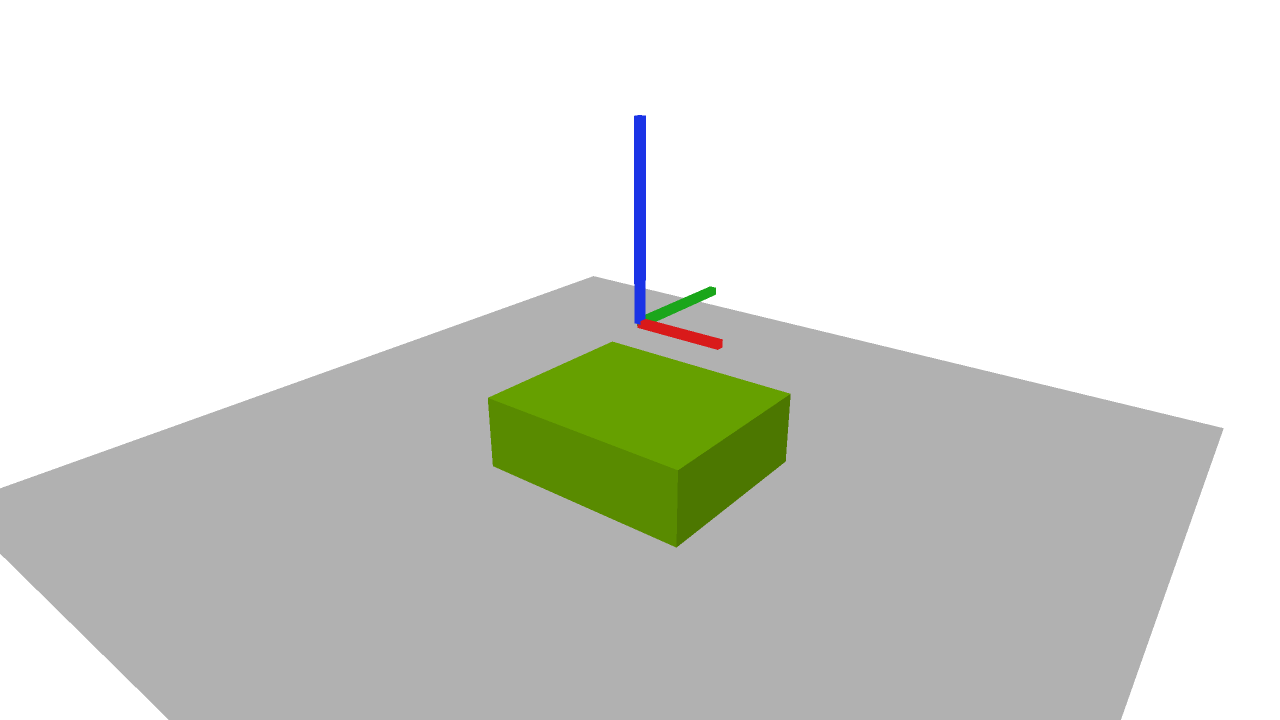

In [15]:
# HIDE/SHOW
show(InertiaBox())

| | Edge along the axis | Moment about the axis |
|---|---|---|
| **Red axis, x** | $a = 0.6$ m | $\tfrac{m}{12}\,(b^2 + c^2) = 0.0483\ \text{kg}\,\text{m}^2$ |
| **Green axis, y** | $b = 0.5$ m | $\tfrac{m}{12}\,(a^2 + c^2) = 0.0667\ \text{kg}\,\text{m}^2$ |
| **Blue axis, z** | $c = 0.2$ m | $\tfrac{m}{12}\,(a^2 + b^2) = 0.1017\ \text{kg}\,\text{m}^2$ |

**Check yourself.**

- Do the engine's tensor and the formula agree? To how many digits?
- After the 30 degree turn, did the numbers change? What does your answer say about the frame in which the engine reports inertia: fixed to the body, or fixed to the world?
- The largest moment belongs to the shortest edge. Explain why in one sentence.
- An imported robot link is a thin rod but its inertia is that of a sphere a metre across. What will the simulation do, and where did the bad numbers come from?

## Lab 8: Implicit Functions and Collision Shapes

Handbook 1.5.2 and 1.5.3.

**The idea.** An implicit function $F(x, y, z)$ describes a shape by an equation. It is negative inside, zero on the surface and positive outside, and shapes combine with `min` and `max`. When $F$ is the distance to the surface, contours at small positive values are offset surfaces: free safety margins. Physics engines use exactly these ideas for collision, and the collision shape you choose is a *model* of the mesh, not the mesh.

**In symbols.** A shape is the set of points where its function is negative:

$$
F(\mathbf{x}) < 0 \ \ \text{inside},
\qquad
F(\mathbf{x}) = 0 \ \ \text{on the surface},
\qquad
F(\mathbf{x}) > 0 \ \ \text{outside}
$$

A circle with centre $\mathbf{c}$ and radius $r$ is $F(\mathbf{x}) = \lVert \mathbf{x} - \mathbf{c} \rVert - r$ and two shapes $F_1$ and $F_2$ combine as

$$
\text{union: } \min(F_1, F_2),
\qquad
\text{intersection: } \max(F_1, F_2),
\qquad
\text{difference: } \max(F_1, -F_2)
$$

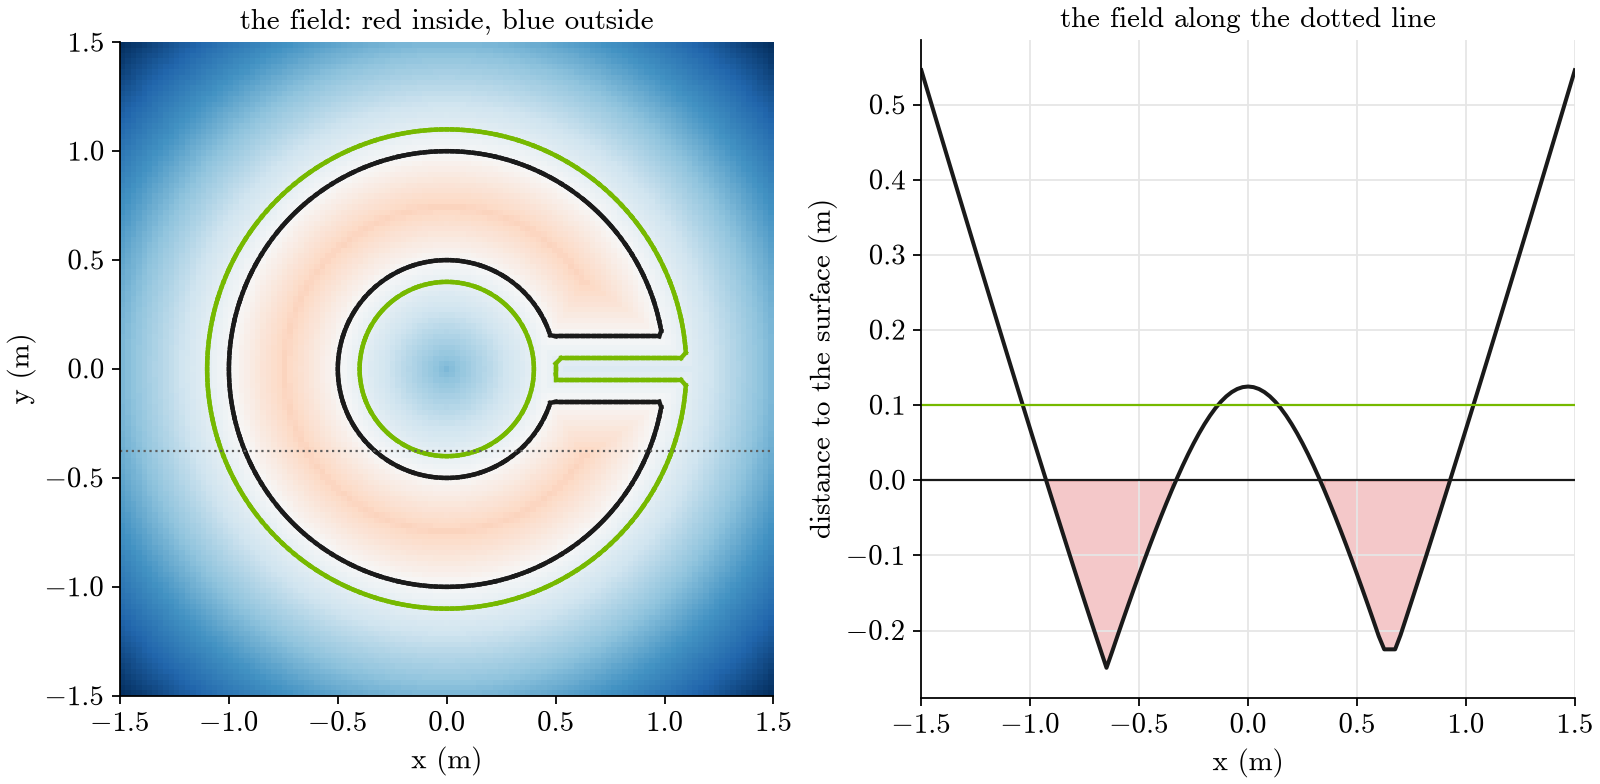

In [16]:
# HIDE/SHOW
show(FieldChart())

| | In the chart | Meaning |
|---|---|---|
| **Inside** | red, $F < 0$ | the part: a disc, minus a hole, minus a slot |
| **Surface** | black line, $F = 0$ | the outline of the part |
| **Offset** | green line, $F = 0.1$ m | the outline moved outward by 10 cm: a safety margin |
| **Cut** | right panel, along the dotted line | $F$ crosses zero where the line enters and leaves the part |

**Steps, part A: no simulator.**

1. Read how a part is made from three distance functions: a disc, minus a hole, minus a slot.

    <details>
    <summary>Listing: demo_part() in labs/vizcore.py</summary>

    ```python
    def demo_part(xs):
        """A part built from three distance functions on the grid
        xs x xs: a disc, minus a hole, minus a slot."""
        X, Y = np.meshgrid(xs, xs, indexing="ij")
        disc = sdf_circle(X, Y, (0.0, 0.0), 1.0)
        hole = sdf_circle(X, Y, (0.0, 0.0), 0.5)
        slot = sdf_box(X, Y, (0.9, 0.0), (0.5, 0.15))
        ring = op_difference(disc, hole)             # disc minus hole
        return op_difference(ring, slot)             # ... minus a slot
    ```

    </details>

2. Build it and contour it. The script also draws the part as text.

    ```bash
    # Spark (isaac)
    python labs/lab08a_sdf.py
    ```

    <details>
    <summary>Expected output</summary>

    ```text
    F = 0.0: 494 contour segments, 9.81 m long  (surface)
    F = 0.1: 522 contour segments, 10.57 m long  (10 cm offset)
    area inside (F < 0): 2.201 m^2
    is the origin inside the part? False (F = +0.50)
    .........................................
    .........................................
    .........................................
    .........................................
    ...............###########...............
    ............#################............
    ..........#####################..........
    .........#########.....#########.........
    ........#######...........#######........
    .......#######.............#######.......
    .......#######...........................
    .......#######...........................
    ........#######...........#######........
    .........#########.....#########.........
    ..........#####################..........
    ............#################............
    ...............###########...............
    .........................................
    .........................................
    .........................................
    .........................................
    ```

    </details>

3. Add a second slot on the opposite side: one more `sdf_box` at `(-0.9, 0.0)` and one more `op_difference` in `demo_part`. Run step 2 again. One more line of code, no mesh editing. Undo it afterwards.

**Steps, part B: the simulator.**

4. Before running, predict. A ball is dropped onto the centre of a flat ring whose hole is wider than the ball. The ring's collision shape is set, in turn, to its convex hull, a convex decomposition, a signed distance field, and the raw triangles. For which settings does the ball fall through?

5. Run the experiment. The line under test is `collide(paths["ring"], approximation)`.

    ```bash
    # Spark (isaac)
    python labs/lab08b_colliders.py
    cat out/colliders.csv
    ```

    For each setting the script prints where the ball came to rest and whether that is on the ring or through the hole. A ball on the ground has its centre at 0.1 m; the ring's top is at 0.55 m.

6. Add `"boundingCube"` to the tuple of approximations in the script, predict, and run again.

**What it looks like.** The scene at the start of every run, `out/lab08.usda`:

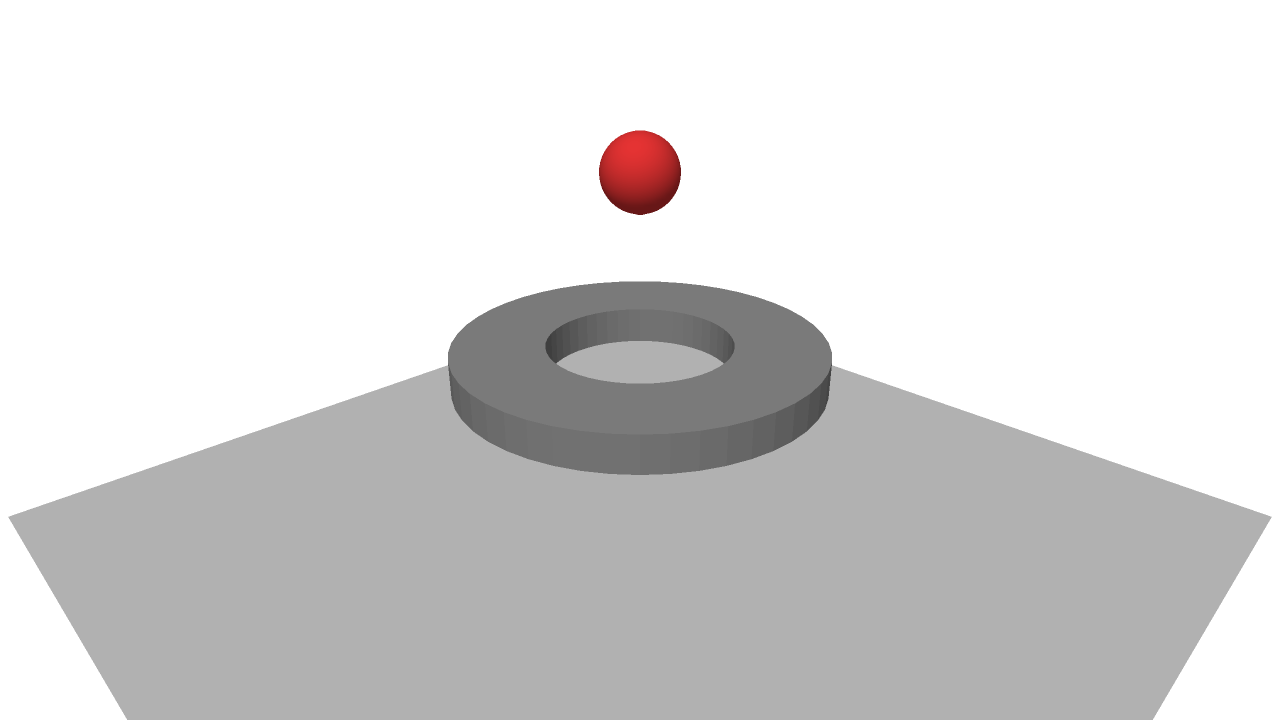

In [17]:
# HIDE/SHOW
show(BallAndRing())

| | Size | Height |
|---|---|---|
| **Ball** | radius 0.1 m | centre 1 m above the ground at the start |
| **Ring** | outer radius 0.5 m, hole radius 0.25 m, 0.1 m thick | top at 0.55 m |
| **Ground** | 2.6 m on a side | $z = 0$ |

The prediction for a convex hull follows from geometry alone: the hull of a ring has no hole. The diagram is that prediction, not a result. Your run in step 5 decides, for the hull and for the other three settings.

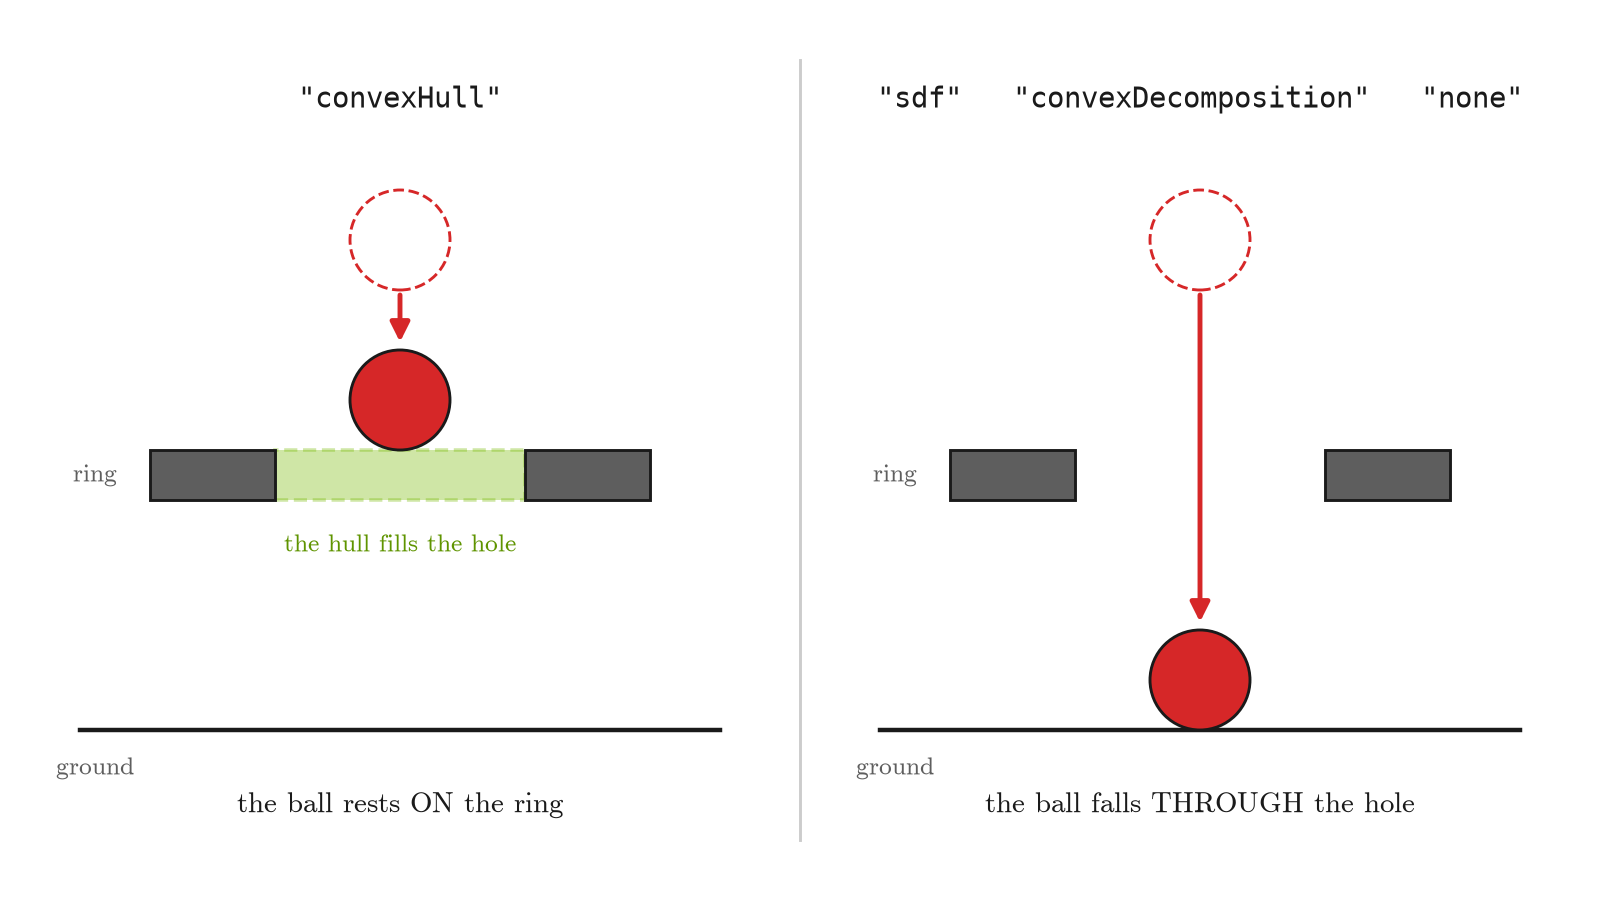

In [18]:
# HIDE/SHOW
show(ColliderDiagram())

| | Collision shape of the ring | Where the ball should rest |
|---|---|---|
| **Left** | `"convexHull"`: the hole is filled | on the ring, centre near 0.65 m |
| **Right** | a shape that keeps the hole | on the ground, centre near 0.1 m |

**Check yourself.**

- Which settings kept the hole? Were you right?
- The picture of the ring is identical in all four runs. What changed?
- Why would anyone choose a convex hull, given what it did here?
- A peg-in-hole task fails in simulation with the peg resting on top of the hole. What do you check first?

## Lab 9: Glyphs

Handbook 1.5.4.

**The idea.** A glyph is an object whose position, direction, size or colour is driven by data. A hedgehog line is the simplest glyph. USD draws thousands of copies of one prototype cheaply with a *point instancer*: one cone, many positions, orientations and scales.

**In symbols.** At a sample with unit surface normal $\mathbf{n}$ the cone's own axis is turned onto the normal, and its length $\ell$ grows with the slope $1 - n_z$ of the terrain:

$$
\ell = 0.12\,\bigl(1 + 6\,(1 - n_z)\bigr)\ \text{m}
$$

**Steps.**

1. Read the instancer: one prototype and three per-glyph arrays.

    <details>
    <summary>Listing: labs/lab09_glyphs.py, the point instancer</summary>

    ```python
    # ONE cone is stored; the instancer draws it once per sample.
    glyphs = UsdGeom.PointInstancer.Define(stage, "/World/Glyphs")
    cone = look.mesh("cone", *look.cone_shape(scenes.LAB09_RADIUS),
                     look.WHITE_RGB, lit=False)
    matte = UsdShade.Material.Get(stage, "/World/Look/Matte")
    proto = look.usd_mesh(stage, "/World/Glyphs/Proto", cone, matte)
    glyphs.CreatePrototypesRel().AddTarget(proto.GetPath())
    glyphs.CreateProtoIndicesAttr([0] * len(bases))
    glyphs.CreatePositionsAttr(bases.tolist())
    glyphs.CreateOrientationsAttr(
        [Gf.Quath(*map(float, q)) for q in quats])
    glyphs.CreateScalesAttr([(1.0, 1.0, float(s)) for s in lengths])
    ```

    </details>

2. Draw the terrain's surface normals as cones. Then connect the client: white cones stand on the terrain, longer where it is steeper.

    ```bash
    # Spark (isaac)
    python labs/lab09_glyphs.py --stream
    ```

    <details>
    <summary>Expected output</summary>

    ```text
    289 glyphs from one prototype prim
    steepest sample: normal [-0.08  0.52  0.85], cone length 0.229 m
    ```

    </details>

3. Confirm there is only one cone in the file.

    ```bash
    # Spark
    grep -c 'def Mesh "Proto"' out/lab09.usda      # 1
    ```

4. Change the density: add `--every 2` (1089 glyphs) or `--every 8` (81 glyphs) to the command of step 2, and note the size of `out/lab09.usda` each time.

**What it looks like.** The scene the lab saves, `out/lab09.usda`:

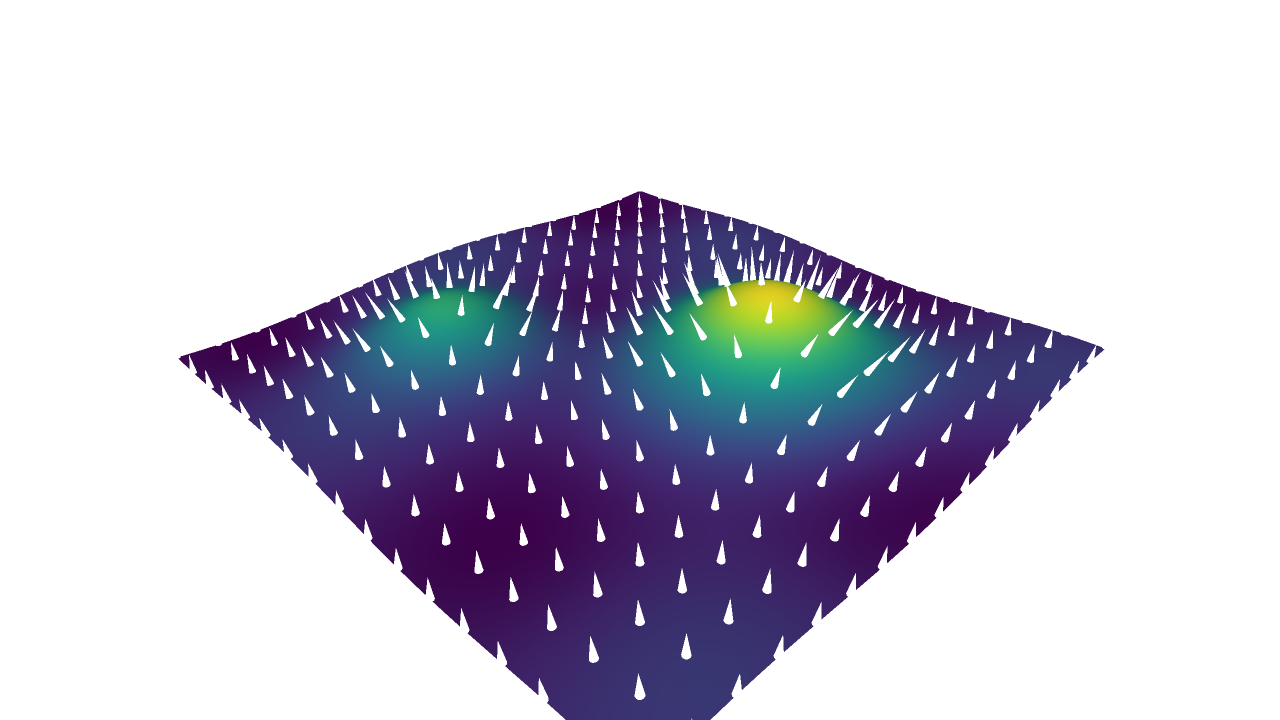

In [19]:
# HIDE/SHOW
show(Glyphs())

| | One value per glyph | Driven by |
|---|---|---|
| **Position** | a point of the terrain | every fourth sample: $17^2 = 289$ glyphs |
| **Orientation** | a quaternion that turns the cone's axis onto $\mathbf{n}$ | the surface normal |
| **Scale** | the length $\ell$ of the cone | the slope $1 - n_z$ |

**Check yourself.**

- Which three per-glyph arrays does the script give the instancer?
- Four times as many glyphs: how much did the file grow? What would it have cost if every cone were its own mesh?
- At `--every 2`, can you still read the slope? At `--every 8`, what did you lose?
- The cones are stretched along their length only. The handbook warns against scaling a glyph in all directions by the data value. Why?

## Lab 10: Probing

Handbook 1.5.6.

**The idea.** Probing samples one dataset at the points of another. Every simulated sensor is a probe: a camera probes the scene with a grid of rays, a lidar with a fan. Sample too sparsely and thin things vanish between samples.

**In symbols.** A fan of $n$ rays spread over an angle $\Theta$ leaves a gap $\Delta\theta$ between neighbouring rays, and an object of width $w$ at a distance $d$ covers an angle of about $\alpha$ radians:

$$
\Delta\theta = \frac{\Theta}{n - 1},
\qquad
\alpha \approx \frac{w}{d}
$$

The fan is certain to hit the object only when $\Delta\theta \le \alpha$ holds.

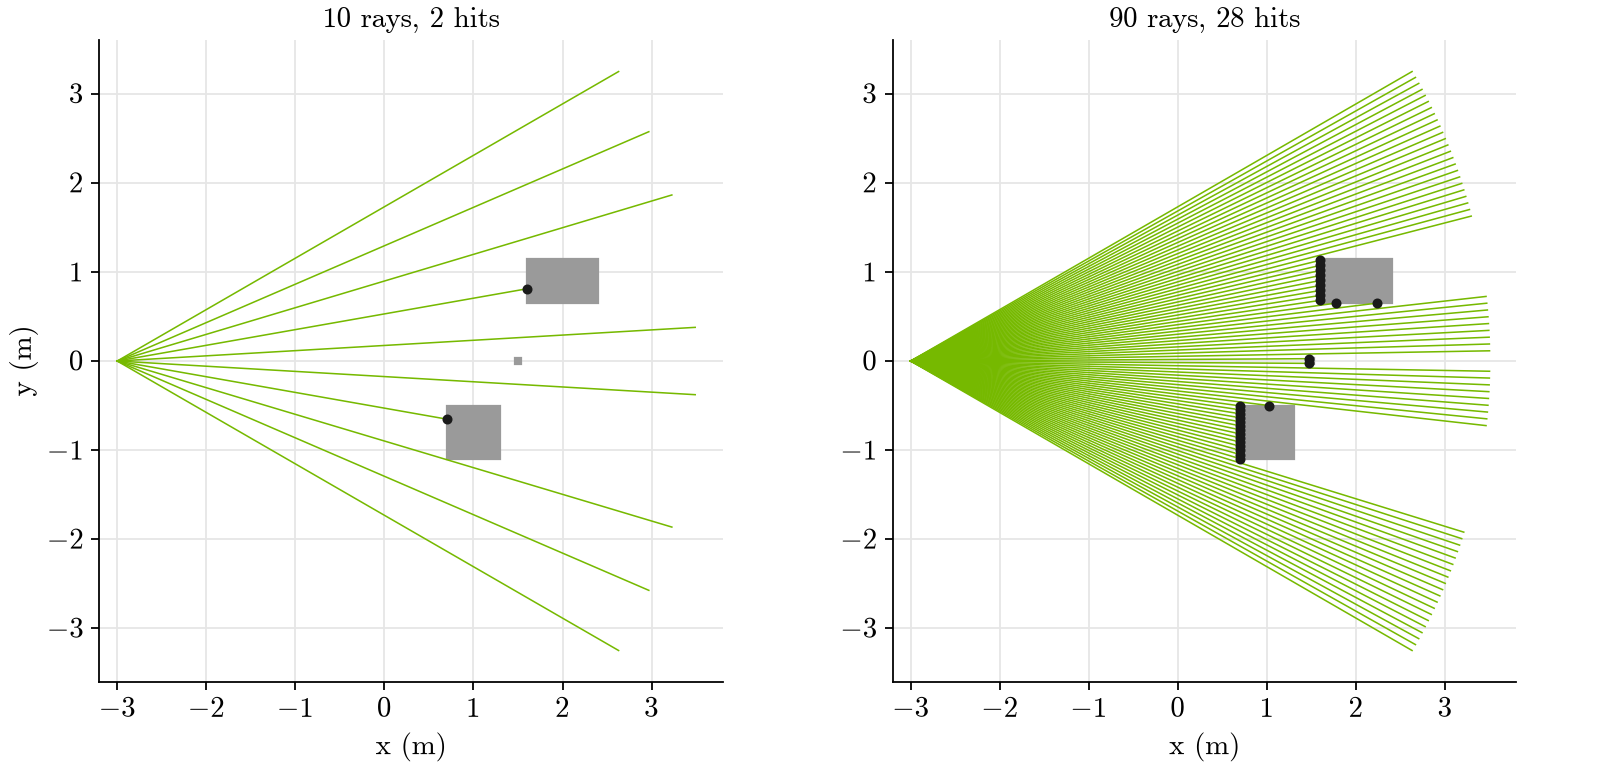

In [20]:
# HIDE/SHOW
show(ProbeChart())

| | Fan of 10 rays | Fan of 90 rays |
|---|---|---|
| **Gap between rays** | $\Delta\theta = 60^\circ / 9 = 6.67^\circ$ | $\Delta\theta = 60^\circ / 89 = 0.67^\circ$ |
| **Hits** | 2 | 28 |
| **Hits on the thin leg** | 0 | 2 |

The distances in this chart come from the reference ray caster in `labs/vizcore.py`, not from the physics engine.

**Steps.**

1. Read the probe: one ray cast per direction, asked of the physics engine.

    <details>
    <summary>Listing: labs/lab10_probe.py, the ray casts</summary>

    ```python
    query = omni.physics.core.get_physics_scene_query_interface()
    measured = {}
    for n, _rgb, _width, _lift in scenes.LAB10_FANS:
        directions = vc.ray_fan(n, scenes.LAB10_FOV)
        dist = np.full(n, np.inf)
        for i, d in enumerate(directions):
            ok, hit = query.raycast_closest(
                scenes.LAB10_ORIGIN, tuple(map(float, d)),
                scenes.LAB10_MAX, True)
            if ok:
                dist[i] = hit.distance
    ```

    </details>

2. Probe two boxes and a thin leg with a fan of 10 rays and a fan of 90 rays, both 60 degrees wide.

    ```bash
    # Spark (isaac)
    python labs/lab10_probe.py --stream
    ```

    For each fan the script prints the number of hits, how many rays the thin leg should catch, and the largest difference between the engine's distances and the reference ray caster. The script adds the rays to the scene as rods: red for the fan of 10, green for the fan of 90.

3. Find the threshold. In `scenes.py` change the `10` in `LAB10_FANS` to 30, then 45, then 60, and run step 2 each time.

**What it looks like.** The scene the lab saves, `out/lab10.usda`. The rays in this picture are drawn to the reference distances.

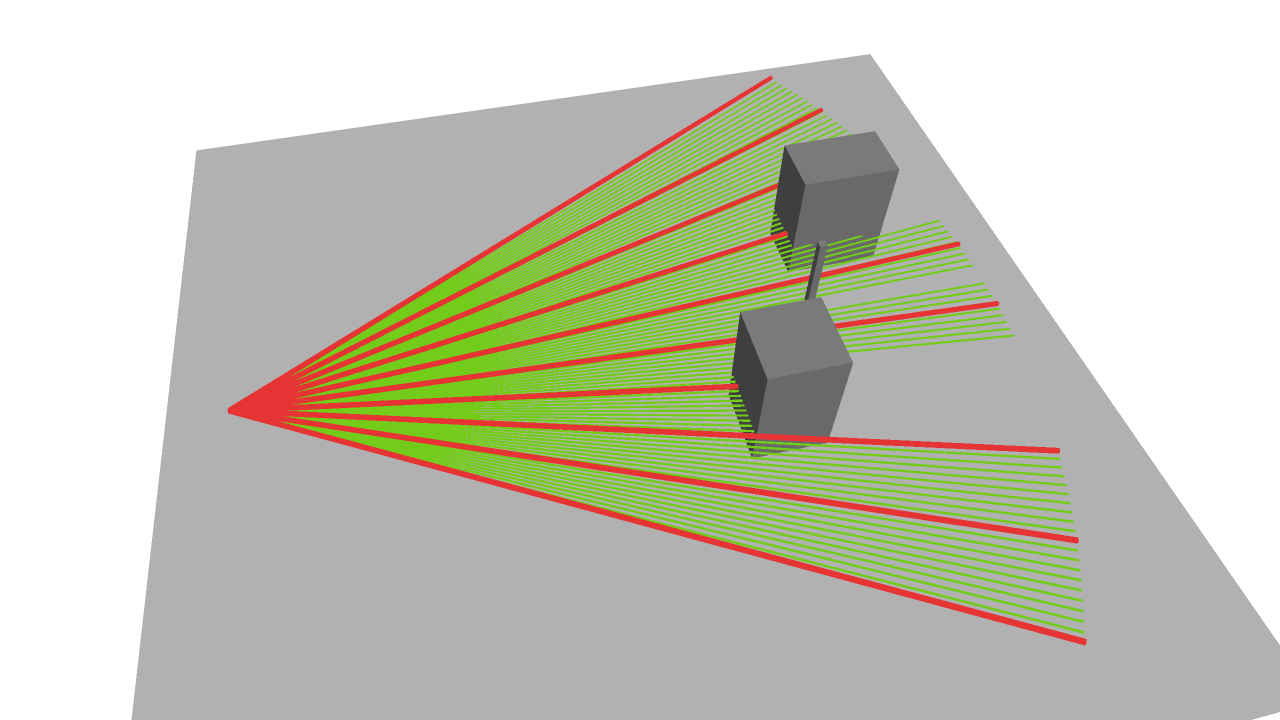

In [21]:
# HIDE/SHOW
show(RayFans())

| | In the picture | Size |
|---|---|---|
| **Sensor** | where the two fans start | 0.3 m above the ground, looking along the x axis |
| **Boxes** | two grey boxes | 1 m high |
| **Leg** | the thin grey post between them | 6 cm wide, 4.5 m from the sensor |
| **Fans** | red: 10 rays; green: 90 rays | both $\Theta = 60^\circ$ wide |

**Check yourself.**

- Do the engine's distances agree with the reference? What is the largest difference?
- The leg is 6 cm wide and 4.5 m away. What angle does it cover? What ray spacing guarantees a hit?
- What is the smallest number of rays in a 60 degree fan that always sees it?
- More rays cost compute. Name one other way to avoid missing the leg.

## Lab 11: Data Reduction

Handbook 1.5.7.

**The idea.** Data grows faster than the ability to draw or simulate it, so you reduce it first and accept an error. Subsampling keeps every n-th sample of regular data. Decimation does the equivalent for arbitrary meshes. The question is always how much error each step of reduction costs.

**In symbols.** Keeping one sample in every $k$ along both axes turns a grid of $n \times n$ points into one with $(n - 1)/k + 1$ points on a side. The error is measured after rebuilding the full grid $\hat{z}$ from the reduced one by linear interpolation:

$$
e_{\max} = \max_i\,\lvert z_i - \hat{z}_i \rvert,
\qquad
e_{\text{rms}} = \sqrt{\frac{1}{N} \sum_{i=1}^{N} (z_i - \hat{z}_i)^2}
$$

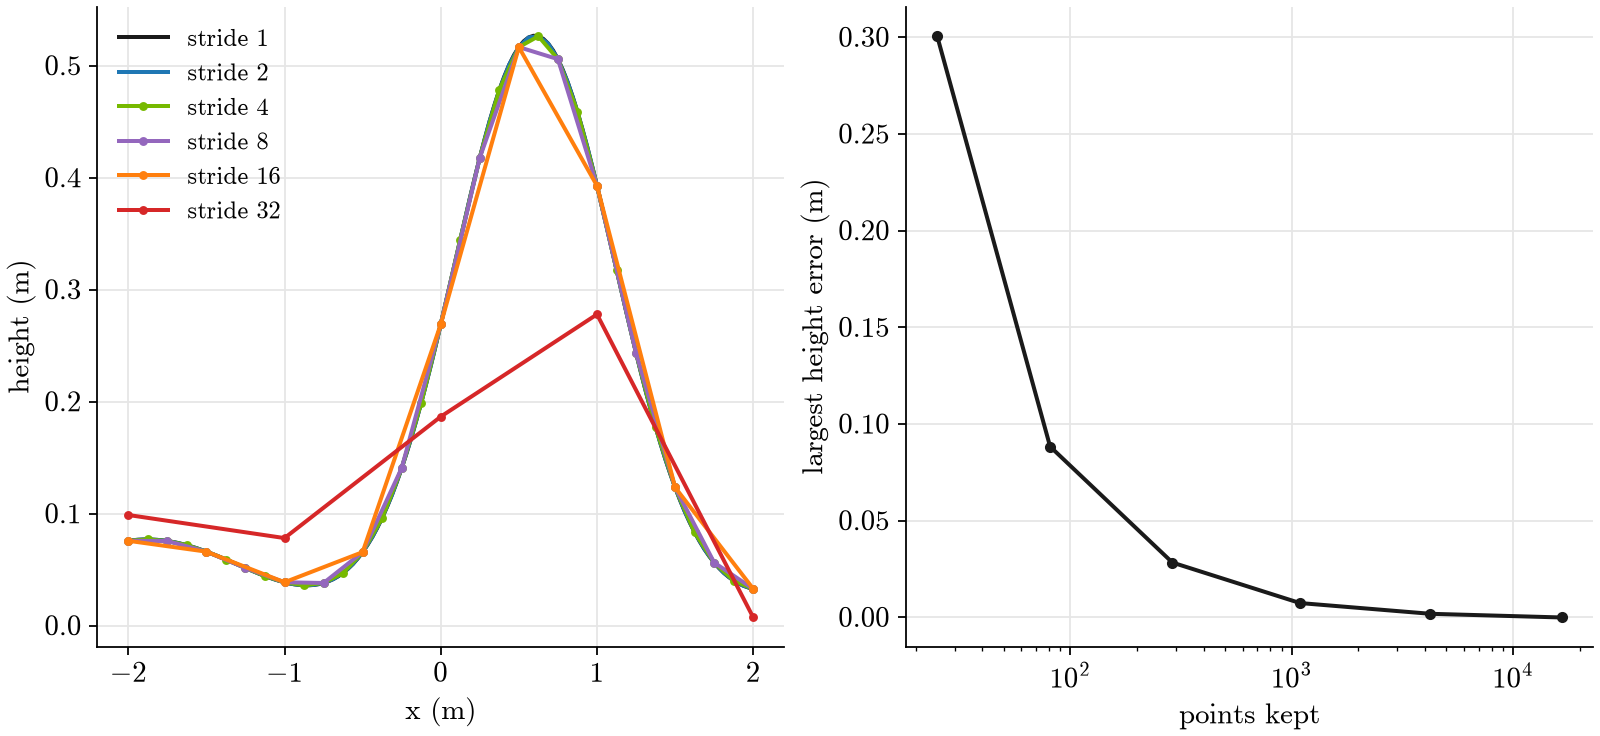

In [22]:
# HIDE/SHOW
show(ReductionChart())

| | Points kept of 16641 | Largest error $e_{\max}$ |
|---|---|---|
| **Stride 2** | 4225 | 0.19 cm |
| **Stride 8** | 289 | 2.84 cm |
| **Stride 32** | 25 | 30.09 cm |

**Steps.**

1. Measure it for the terrain. No simulator is started.

    ```bash
    # Spark (isaac)
    python labs/lab11_reduction.py
    ```

    <details>
    <summary>Expected output</summary>

    ```text
    stride  points   quads   max error   rms error
        1   16641   16384   0.0000 m   0.0000 m
        2    4225    4096   0.0019 m   0.0003 m
        4    1089    1024   0.0075 m   0.0011 m
        8     289     256   0.0284 m   0.0045 m
       16      81      64   0.0884 m   0.0167 m
       32      25      16   0.3009 m   0.0578 m
    ```

    </details>

2. See what the reduction does to the scene file. Note the file size each run prints.

    ```bash
    # Spark (isaac)
    python labs/lab01_dataset.py --n 129 --stride 1
    python labs/lab01_dataset.py --n 129 --stride 8
    ```

3. Look at the coarse one: run the second command with `--stream`.

**What it looks like.** The coarse terrain of step 2, with one sample in eight kept:

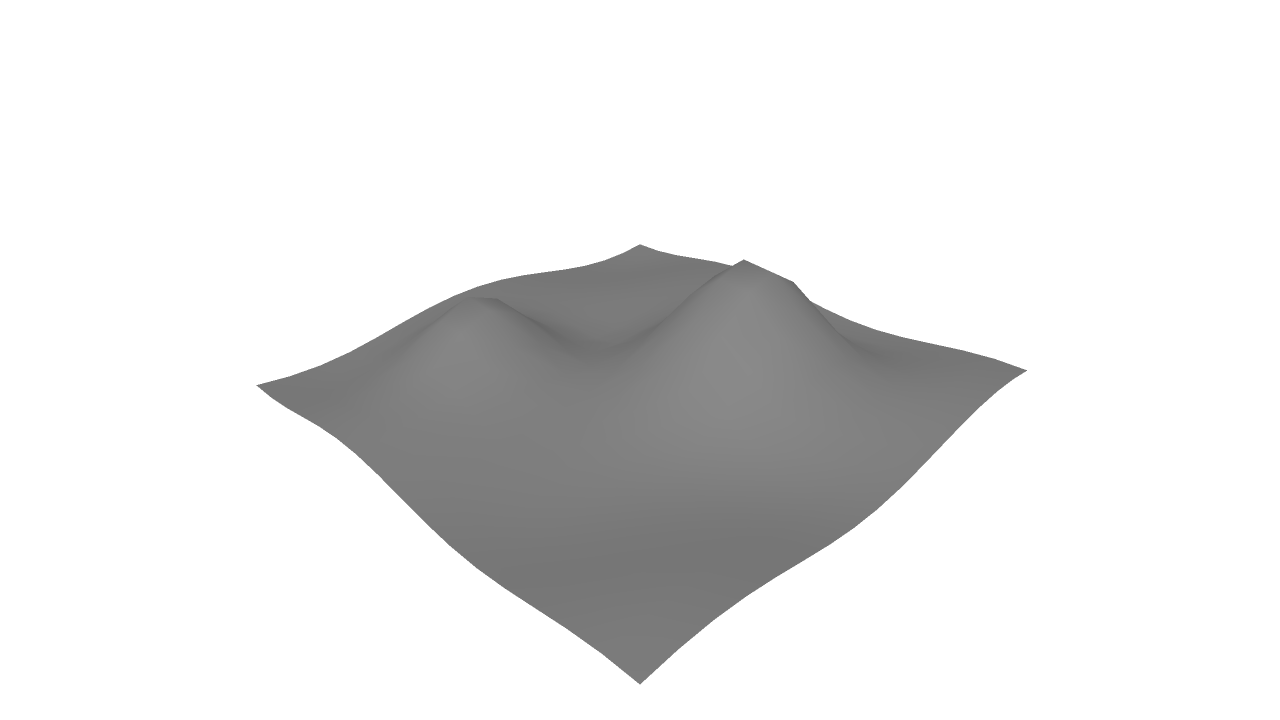

In [23]:
# HIDE/SHOW
class CoarseTerrain(LabScene):
    """The terrain with one sample in eight kept"""

    def build(self):
        return scenes.lab01(n=129, stride=8, taller=True)


show(CoarseTerrain())

| | Full grid | Stride 8 |
|---|---|---|
| **Points** | $129^2 = 16641$ | $17^2 = 289$ |
| **Triangles** | $2 \times 128^2 = 32768$ | $2 \times 16^2 = 512$ |
| **Largest error** | none | 2.84 cm before the heights are doubled |

**Check yourself.**

- What is the largest stride that keeps the error under 1 cm? By what factor did the point count fall?
- Each doubling of the stride divides the points by four. By roughly what factor does the maximum error grow?
- Lab 8 was also data reduction. What was reduced there, and what was the cost?

## What You Built

| | Technique | Where you met it in Isaac Sim |
|---|---|---|
| **1.1** | Topology, geometry, attributes | The three attribute groups of a USD mesh |
| **1.1.2** | Source, filter, sink | `scenes.py` builds data, `look.py` writes prims, the renderer draws |
| **1.2.1** | Colour mapping | `displayColor` on a mesh; a depth camera image |
| **1.2.2** | Contouring | Contour rods on the terrain; collision surfaces from distance fields |
| **1.3.1** | Hedgehogs | Velocity rods added to the scene |
| **1.3.4** | Integration | The physics time step |
| **1.3.5** | Streamlines and pathlines | Trails of thrown bodies |
| **1.4** | Tensor ellipsoids | Inertia tensors read from the engine |
| **1.5.2, 1.5.3** | Implicit functions and modeling | Collision approximations, signed distance fields |
| **1.5.4** | Glyphs | Point instancers |
| **1.5.6** | Probing | Ray casts and cameras |
| **1.5.7** | Data reduction | Subsampled meshes, simplified colliders |

The first column is the section of the handbook.

**Keep the numbers.** Each lab leaves its data in `out/`: `depth.npy`, `contours.npz`, `vectors.npz`, `timestep_*.csv`, `inertia.npz`, `probe.npz` and `colliders.csv`. They load with `numpy.load` and `numpy.loadtxt`, on the Spark or on the Mac.

## If Something Fails

| | What to do |
|---|---|
| `ModuleNotFoundError: No module named 'isaacsim'` | The environment is not active. Run `conda activate isaac`. |
| **A lab stops at an** `isaacsim` **import or call** | The scripts use the `isaacsim.core.experimental` modules of Isaac Sim 6.2. Check `pip show isaacsim`. Almost all simulator calls are in `labs/simlab.py`; what a lab draws goes through plain USD in `labs/look.py`. A version difference will show up in `simlab.py` or in the few `isaacsim` imports at the top of a lab. |
| **Nothing appears in the streaming client** | Only one stream can run at a time, and it must be a script started with `--stream`. See Troubleshooting on the page Isaac Sim on a DGX Spark. |
| **A body falls through the ground or an obstacle** | It has no collider. Every lab calls `collide(...)` for the things that should collide, the ground included; check that line. |
| `no depth data after 120 frames` **in Lab 3** | The renderer was still loading. Run the lab again; the second start is faster. |
| **Your capture is brighter, darker or more contrasty than the preview** | See the end of Step 4 on the page Isaac Sim on a DGX Spark: `DOME_INTENSITY` in `labs/look.py`, and the renderer's tone mapping. |

## Sources

- W. J. Schroeder and K. M. Martin, "Overview of Visualization", Chapter 1 of C. D. Hansen and C. R. Johnson (eds.), *The Visualization Handbook*, Elsevier, 2005. The source chapter is itself drawn from *The Visualization Toolkit: An Object-Oriented Approach to 3D Graphics* (Kitware).
- W. E. Lorensen and H. E. Cline, "Marching Cubes: A High Resolution 3D Surface Construction Algorithm", SIGGRAPH 1987.
- [Isaac Sim: basic usage tutorial](https://docs.isaacsim.omniverse.nvidia.com/latest/introduction/quickstart_isaacsim.html)
- [Isaac Sim: Replicator getting started (cameras and annotators)](https://docs.isaacsim.omniverse.nvidia.com/latest/replicator_tutorials/tutorial_replicator_getting_started.html)
- [Isaac Sim: Python environment installation](https://docs.isaacsim.omniverse.nvidia.com/latest/installation/install_python.html)
- [Isaac Sim source and standalone examples](https://github.com/isaac-sim/IsaacSim)